# Bridge frozen representations and Hallmark biology

This is the human-readable report for the reproducible pipeline in `pipeline/`. It never reimplements analysis logic.

In [1]:
from pathlib import Path
import json, pandas as pd
R=Path('results')
manifest=json.loads((R/'provenance_manifest.json').read_text())
manifest['model'], manifest['cohorts']

({'architecture': {'ffn_dim': 2048,
   'hidden_dim': 512,
   'include_species_embedding': False,
   'num_heads': 8,
   'num_layers': 12,
   'num_species': 2},
  'frozen': True,
  'normalization': 'log1p_tpm',
  'pooling': 'unweighted mean of final-layer contextual gene states',
  'run_id': 'r7hnr92k'},
 {'gtex_samples': 4260, 'tcga_samples': None})

## Q1 — sample-space geometry

In [2]:
g=json.loads((R/'gtex_geometry_summary.json').read_text())
g

{'effective_rank_entropy': 3.052532715352533,
 'effective_rank_participation': 1.7917602730344904,
 'pcs_for_variance': {'0.5': 1, '0.8': 2, '0.9': 4, '0.95': 6, '0.99': 12},
 'samples': 4260}

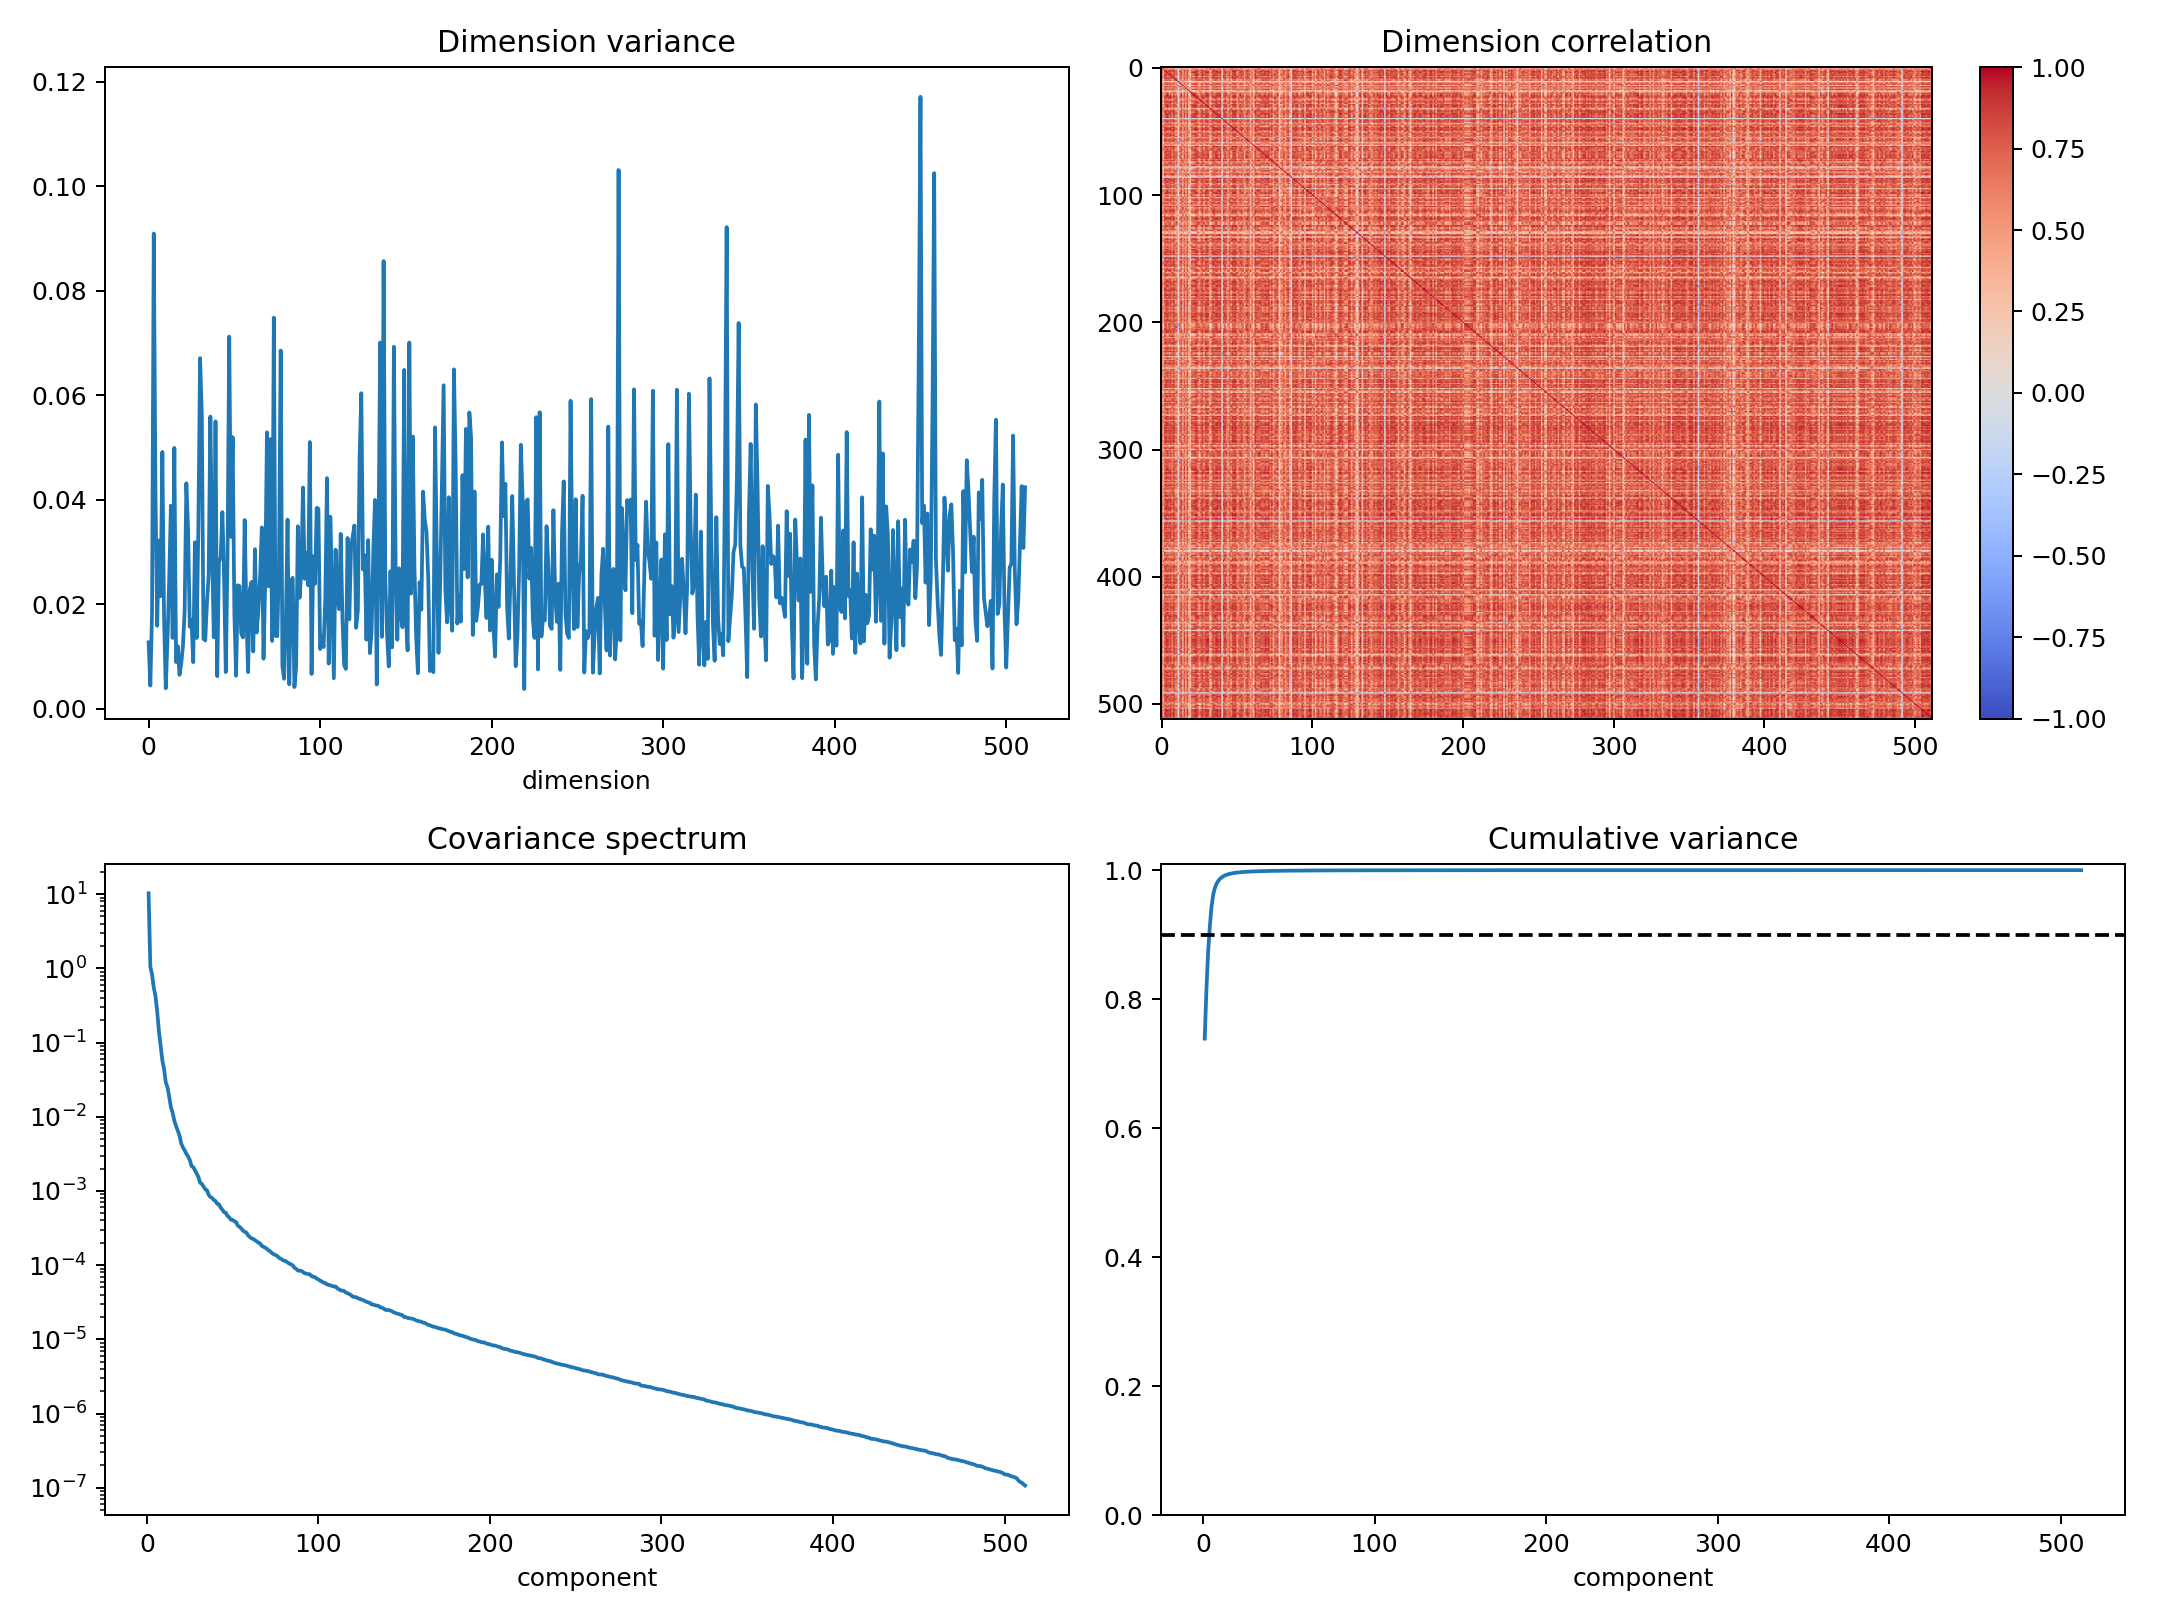

In [3]:
from IPython.display import Image, display
display(Image(filename=R/'gtex_geometry.png'))

## Hallmark targets and distributed probes
Targets are independent within-sample rank-mean Hallmark scores from expression. Feature selection and alpha selection occur inside training folds; GTEx folds are donor-disjoint.

In [4]:
m=pd.read_csv(R/'gtex_nested_hallmark_probe_metrics.csv')
m.groupby(['control','features'])[['pearson','spearman','r2']].mean()

pearson  spearman        r2
control        features                              
observed       1         0.745890  0.634882  0.564337
               5         0.824597  0.726239  0.686869
               10        0.882146  0.807083  0.783256
               25        0.946855  0.909946  0.897593
               512       0.990723  0.982532  0.981508
permuted_label 512      -0.001967 -0.000998 -0.055292

## Contextual gene decoder
The decoder is a new linear multi-label implementation. Its primary evaluation holds out gene identities. GTEx profiles below cover all 4,260 frozen samples and are validated against independent expression-derived targets.

In [5]:
decoder=json.loads((R/'decoder_summary.json').read_text())
validation=pd.read_csv(R/'gtex_mean_profile_validation.csv')
recovery=pd.read_csv(R/'gtex_mean_profile_from_sample_embedding.csv')
decoder, validation[['pearson','spearman']].describe(), recovery[['pearson','spearman']].describe()

({'bridge_frozen': True,
  'contexts': 32,
  'evaluation': 'held-out genes',
  'macro_auprc': 0.0570363618369173,
  'macro_auroc': 0.7496263957182844,
  'macro_prevalence': 0.008663807324315409},
          pearson   spearman
 count  50.000000  50.000000
 mean    0.159969   0.195324
 std     0.377555   0.355985
 min    -0.701186  -0.716593
 25%    -0.048957  -0.027991
 50%     0.195055   0.242203
 75%     0.384603   0.481238
 max     0.903951   0.892596,
          pearson   spearman
 count  50.000000  50.000000
 mean    0.985907   0.972024
 std     0.015650   0.032896
 min     0.913491   0.820214
 25%     0.986052   0.972951
 50%     0.990643   0.982971
 75%     0.993372   0.989019
 max     0.996865   0.994566)

Mean-member scores are the usable contextual-decoder profile. The top-k sensitivity is a negative result because many probabilities saturate. TCGA below uses newly regenerated, provenance-compatible embeddings.

## TCGA replication and zero-shot transfer

In [6]:
tcga=json.loads((R/'tcga_geometry_summary.json').read_text())
transfer=pd.read_csv(R/'gtex_tcga_probe_transfer_summary.csv')
tcga, transfer[['gtex_within_pearson','tcga_within_pearson','pearson','coefficient_cosine_gtex_tcga']].describe()

({'effective_rank_entropy': 5.310532821014545,
  'effective_rank_participation': 2.3463677122721536,
  'pcs_for_variance': {'0.5': 1, '0.8': 4, '0.9': 8, '0.95': 14, '0.99': 38},
  'samples': 9816},
        gtex_within_pearson  tcga_within_pearson    pearson  \
 count            50.000000            50.000000  50.000000   
 mean              0.990723             0.966590   0.794457   
 std               0.007738             0.023629   0.148932   
 min               0.966211             0.906954   0.305072   
 25%               0.986965             0.951964   0.712199   
 50%               0.993555             0.974395   0.852223   
 75%               0.996782             0.983836   0.900493   
 max               0.998856             0.994693   0.943732   
 
        coefficient_cosine_gtex_tcga  
 count                     50.000000  
 mean                       0.365409  
 std                        0.114181  
 min                        0.133304  
 25%                        0.294382 

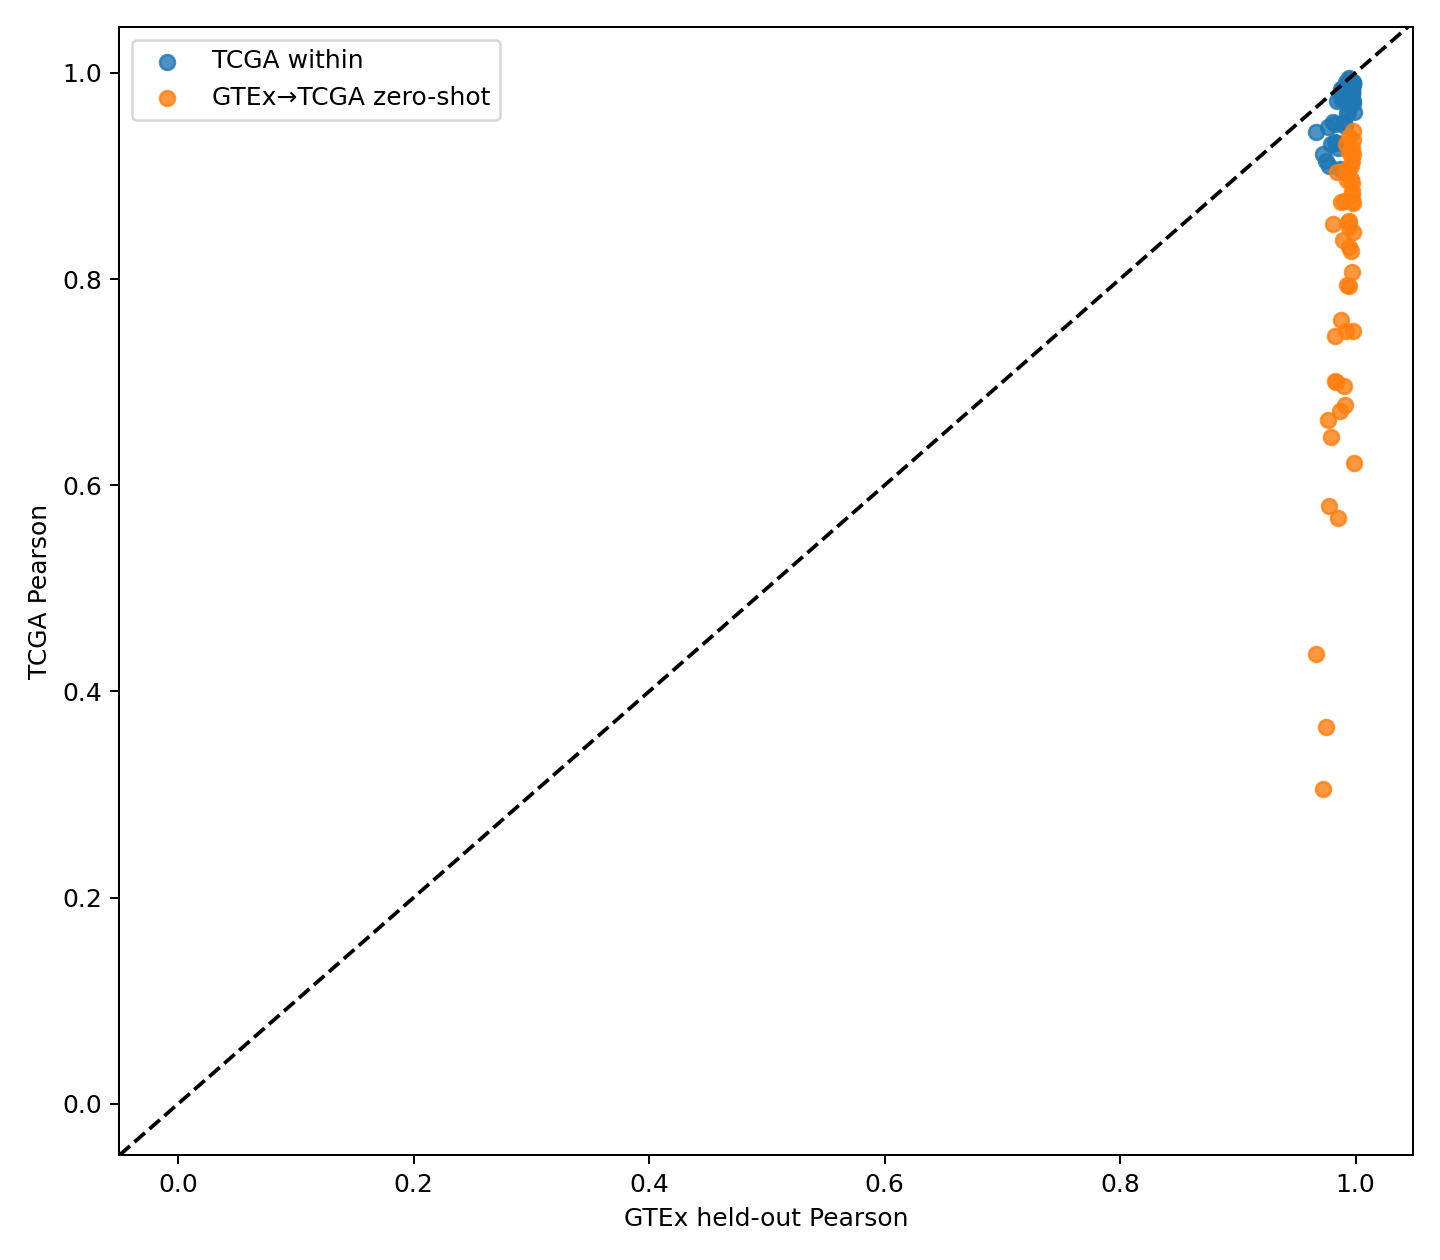

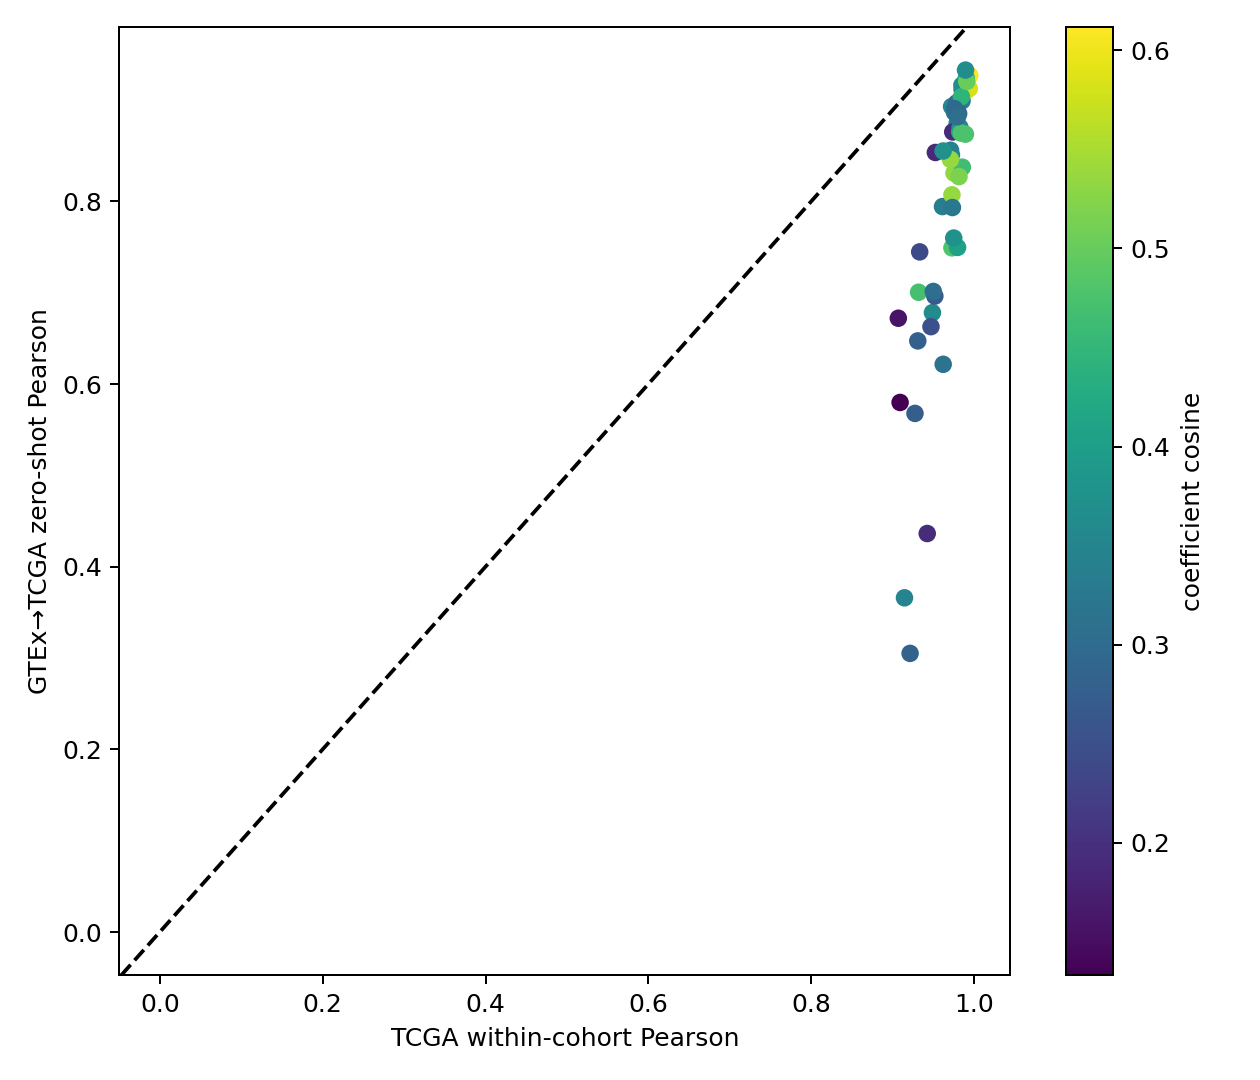

In [7]:
display(Image(filename=R/'gtex_tcga_hallmark_probe_performance.png')); display(Image(filename=R/'gtex_to_tcga_zero_shot_performance.png'))

## Frozen-probe Hallmark landscapes
Heatmaps are descriptive and use a common pathway order and color scale.

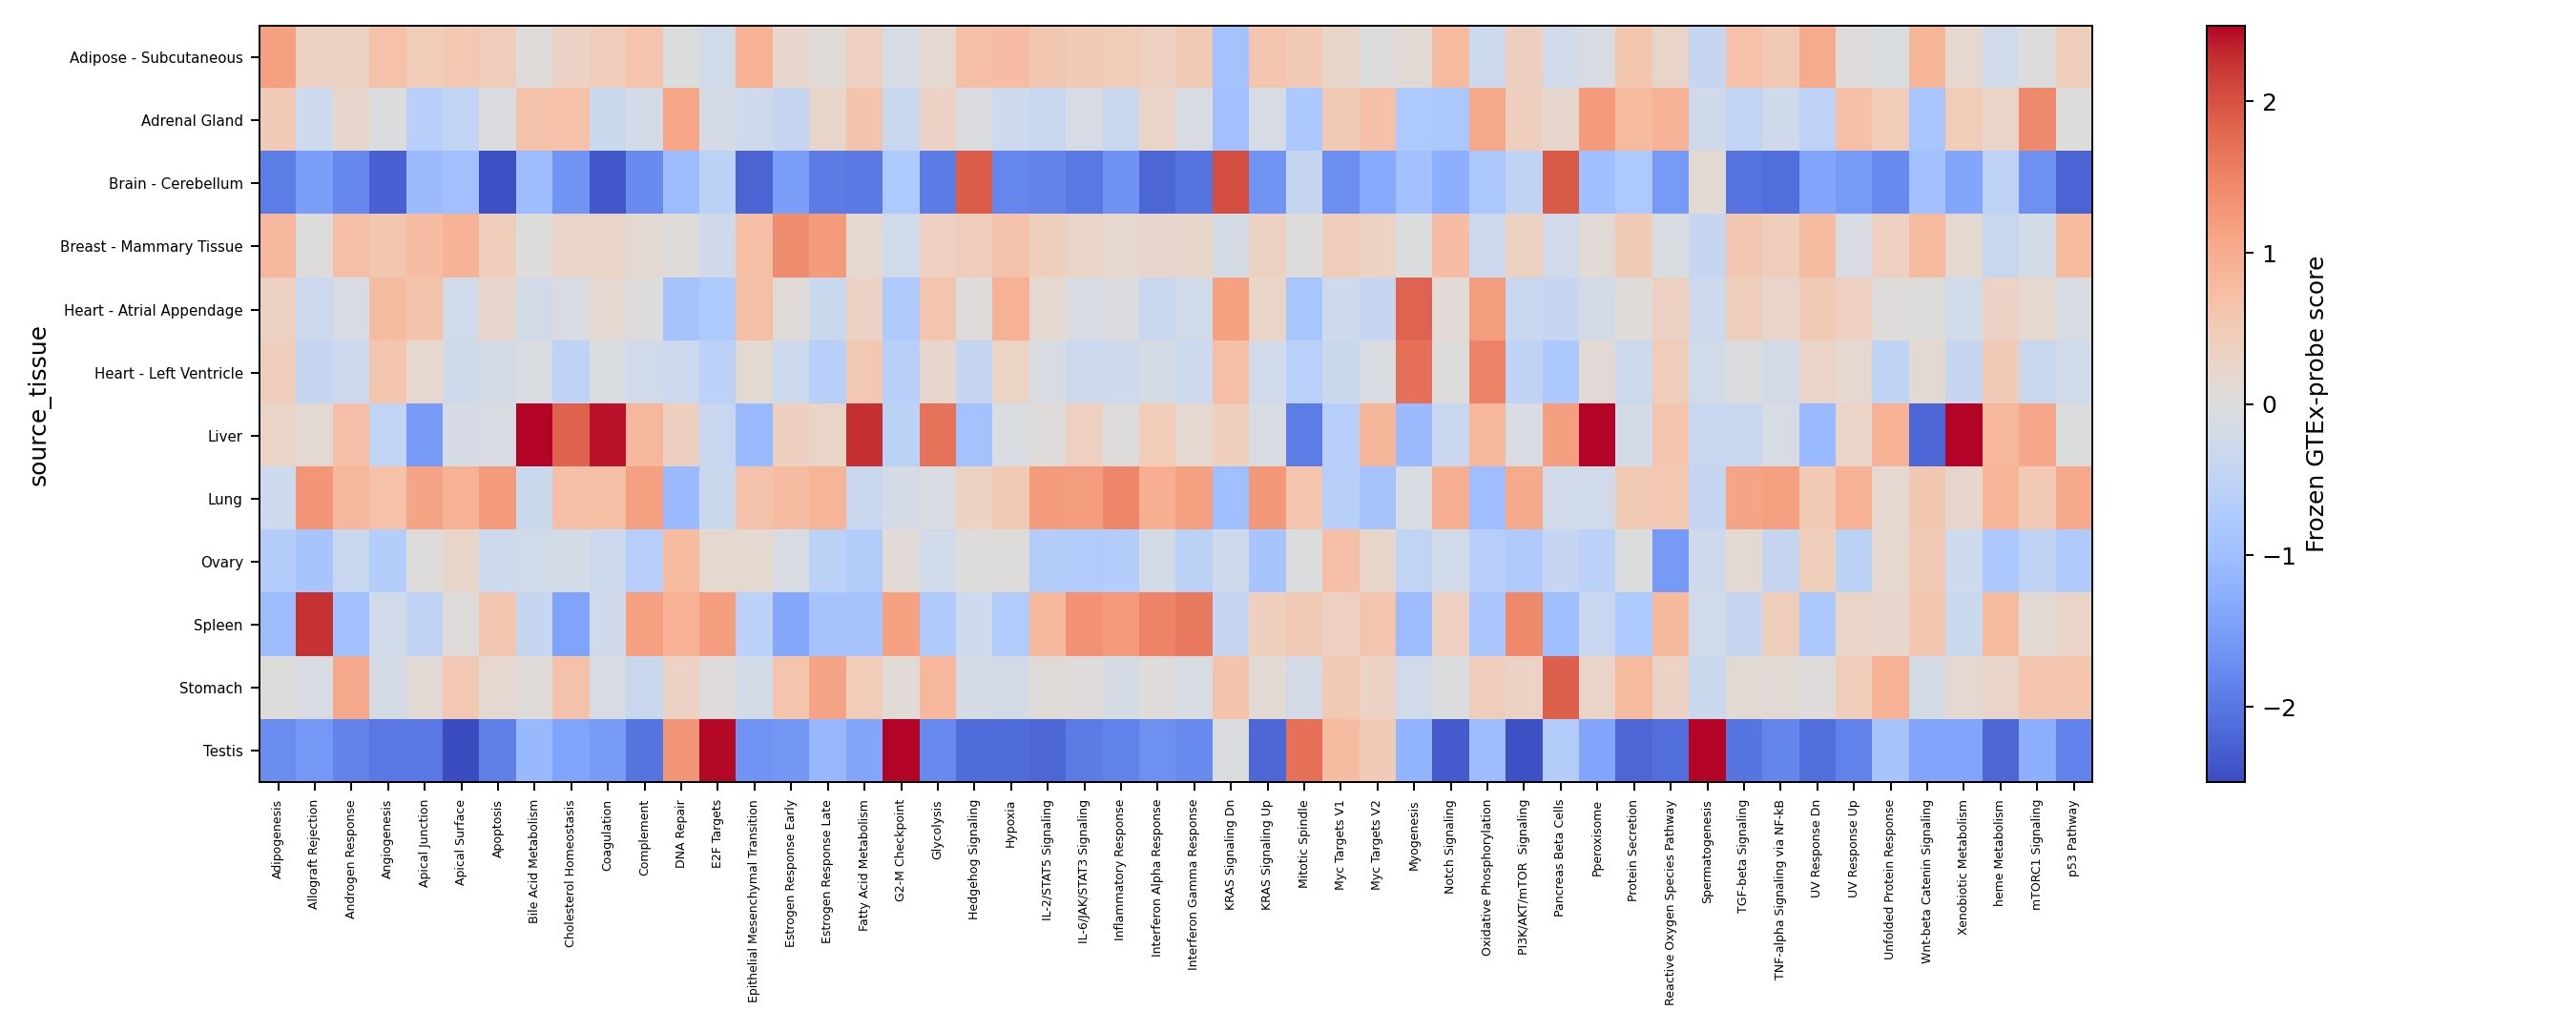

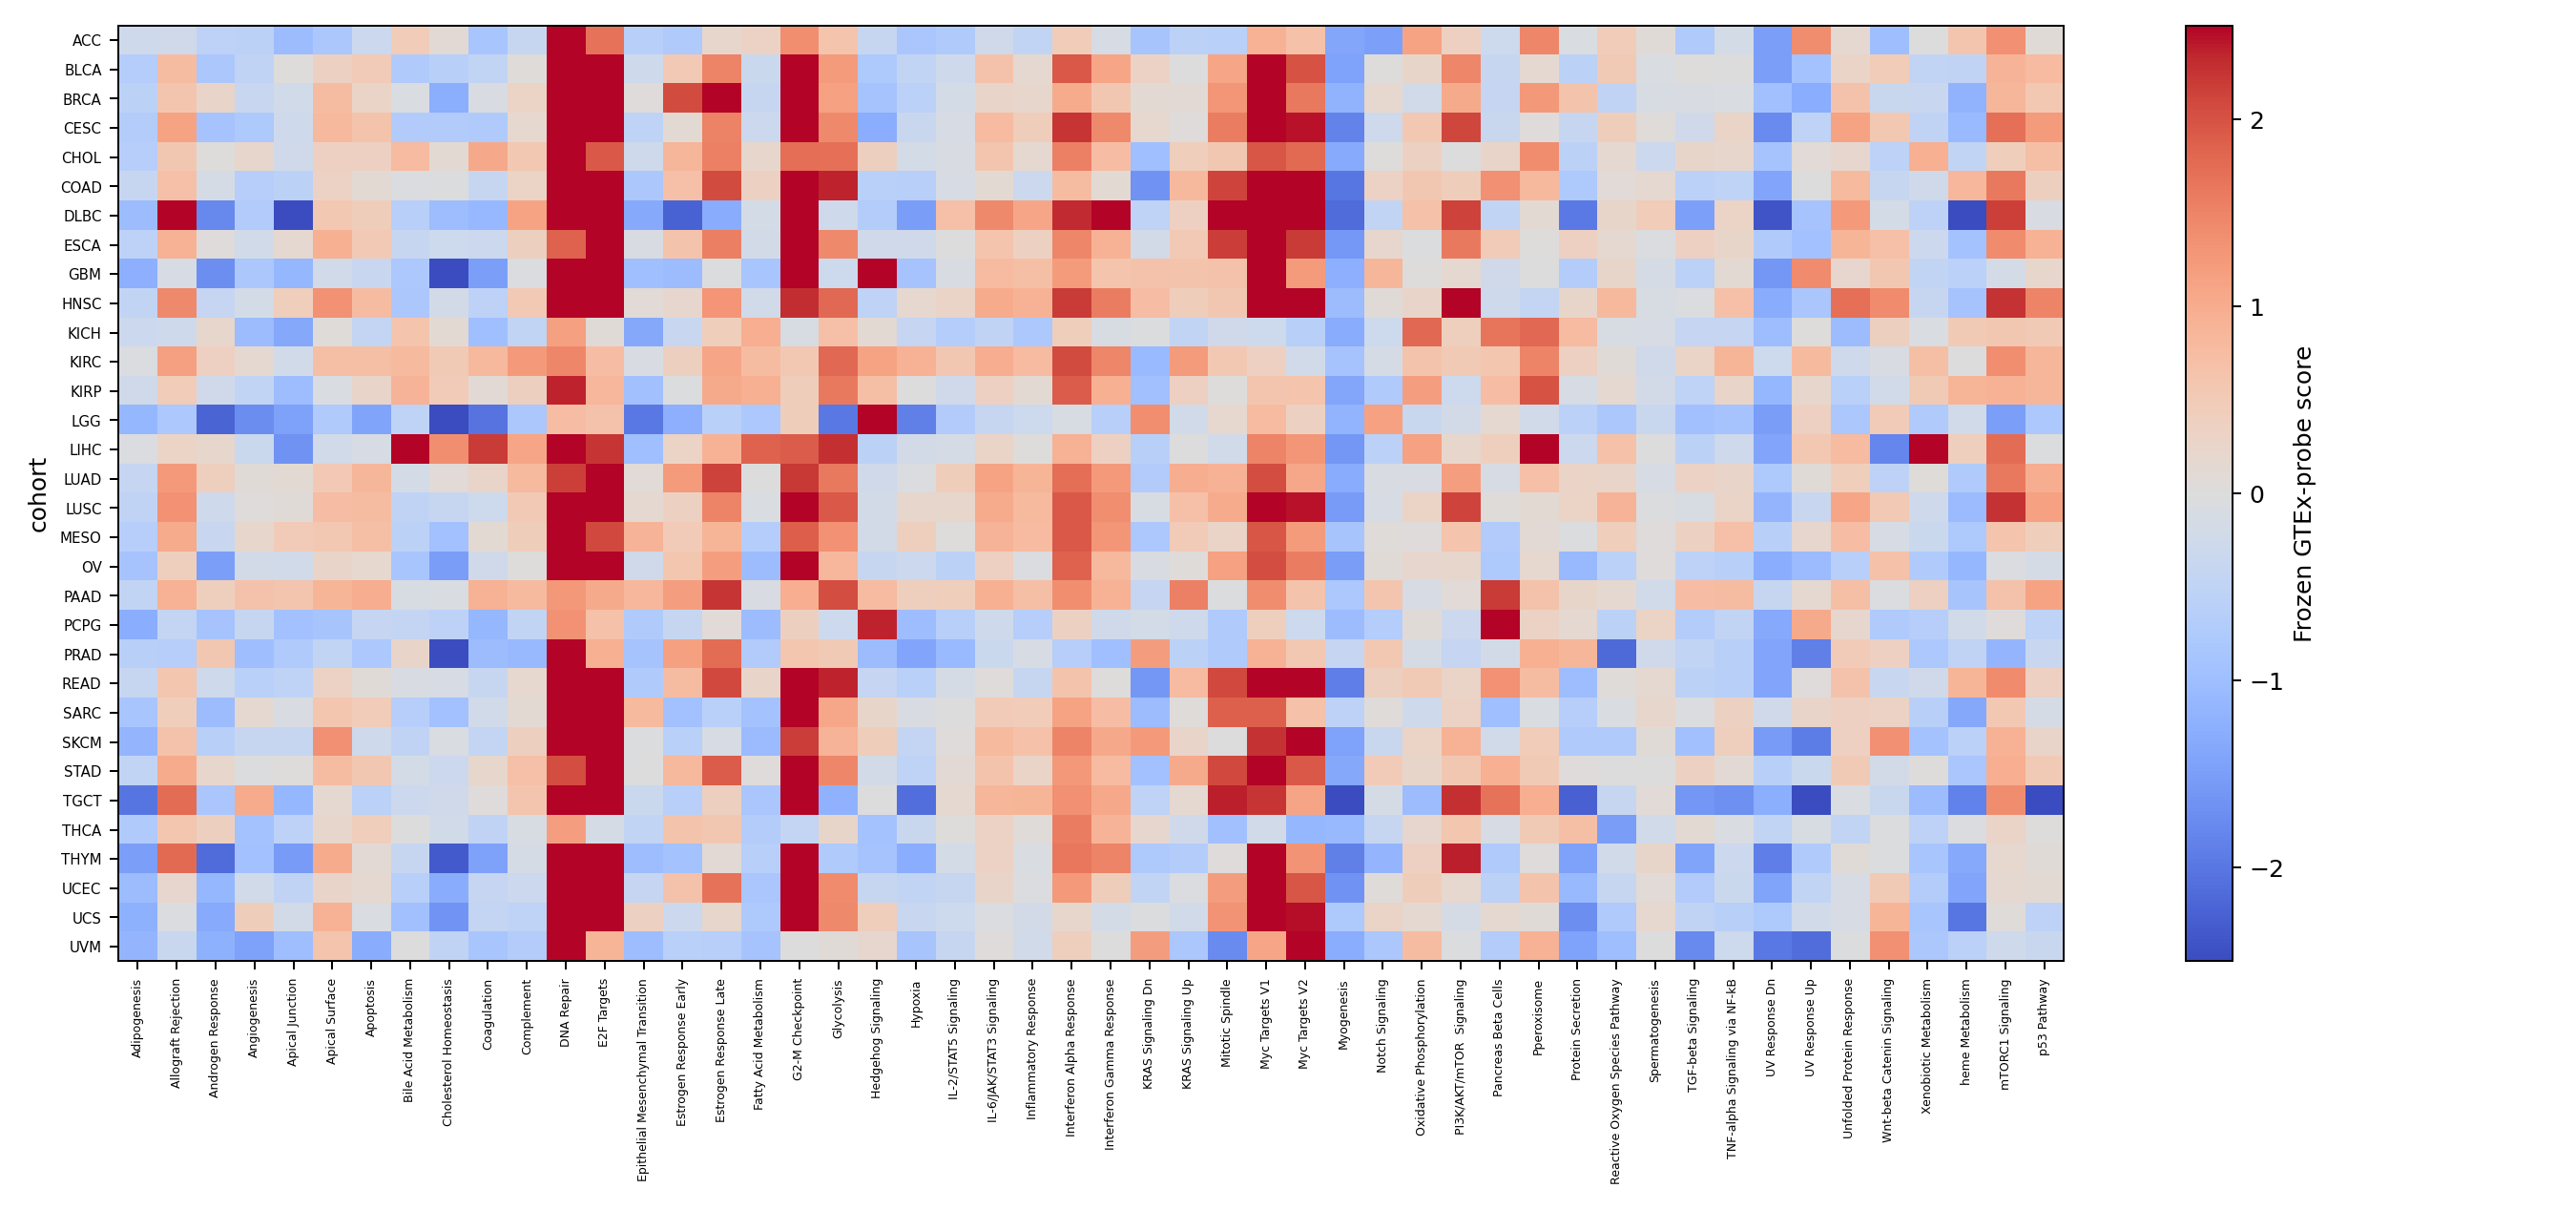

In [8]:
display(Image(filename=R/'gtex_tissue_mean_hallmark_heatmap.png')); display(Image(filename=R/'tcga_cancer_mean_hallmark_heatmap.png'))

## Conventional DE/GSEA and vocabulary control

In [9]:
agreement=pd.read_csv(R/'gsea_universe_and_bridge_agreement.csv')
agreement

,contrast,nes_pearson,rank_spearman,direction_agreement,significant_both,significant_whole_only,significant_vocab_only,significant_jaccard,mean_leading_edge_jaccard,bridge_whole_rank_spearman,bridge_vocab_rank_spearman
0,KIRC_vs_KIRP,0.965316,0.983097,0.96,26,3,0,0.896552,0.85493,0.736086,0.774502
1,LUAD_vs_LUSC,0.984004,0.972245,0.98,20,5,0,0.800000,0.85631,0.598752,0.613445


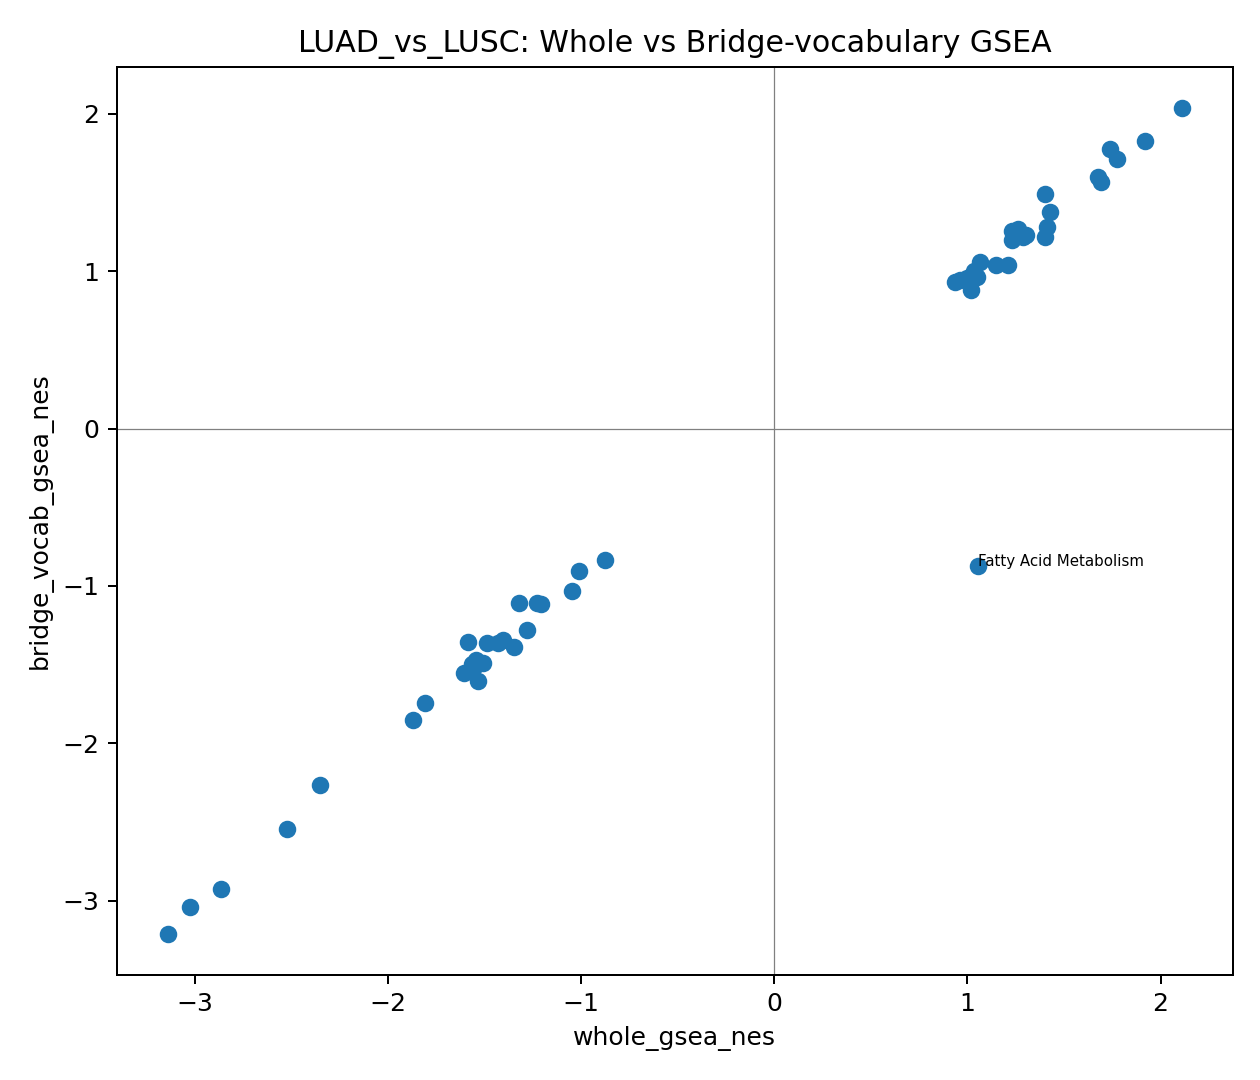

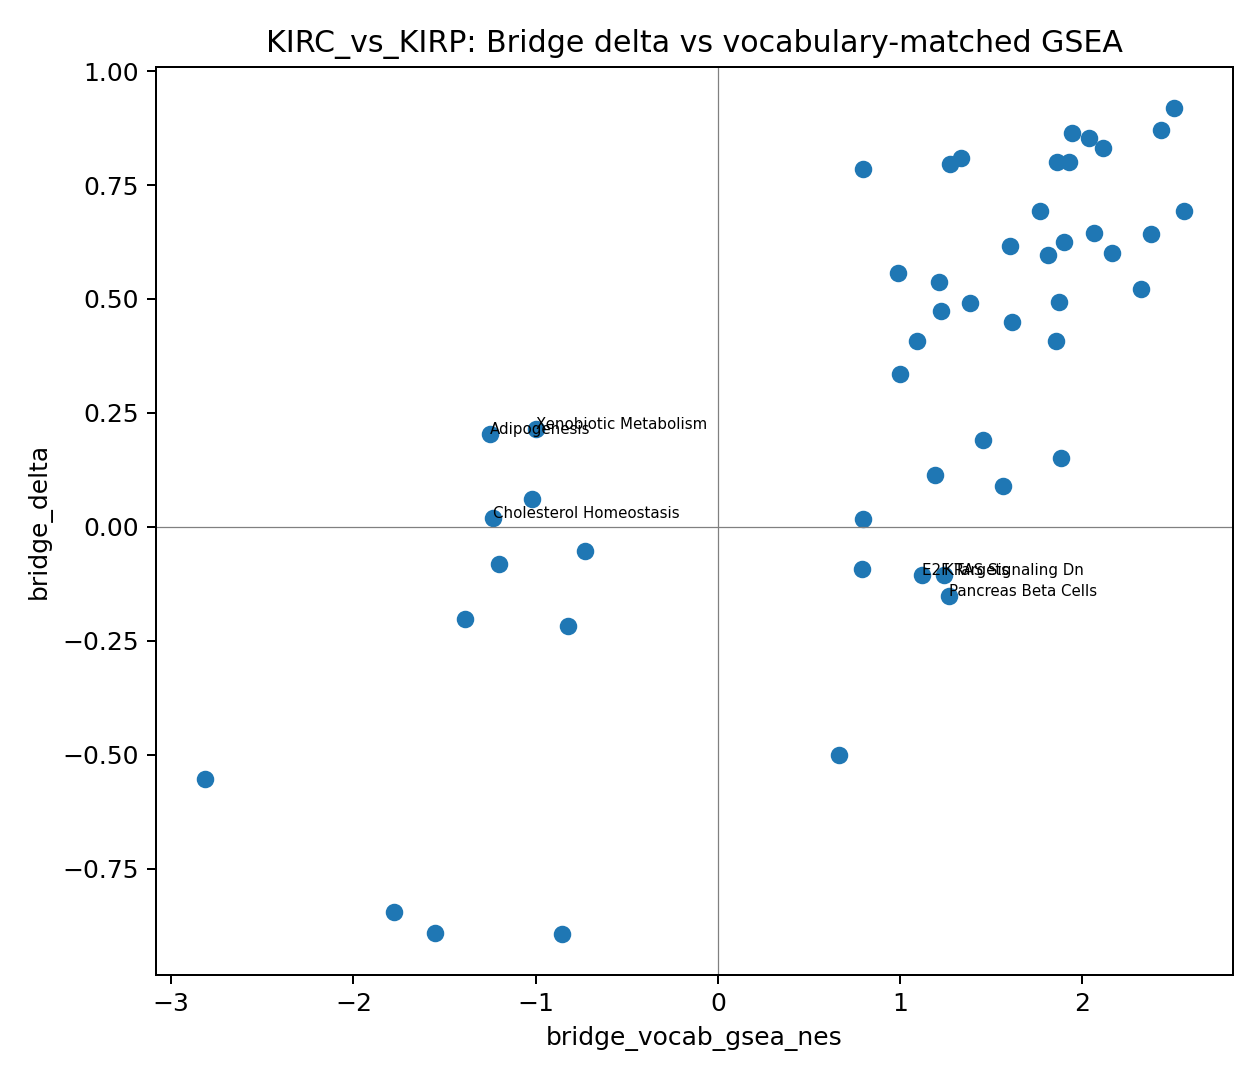

In [10]:
display(Image(filename=R/'LUAD_vs_LUSC_gsea_whole_vs_vocab.png')); display(Image(filename=R/'KIRC_vs_KIRP_bridge_vs_vocab_gsea.png'))

## Numerically validated sample-specific Integrated Gradients
Decoder scores measure Hallmark-like information in a contextual gene representation. IG measures an input gene's contribution to one sample's frozen Bridge→Hallmark prediction relative to the all-zero `log1p(TPM)` reference. It is not cancer-pair attribution. The first-order right-endpoint audit is preserved as a failed numerical control.

In [11]:
ig_steps=pd.read_csv(R/'ig_validation/step_selection_summary.csv')
ig=pd.read_csv(R/'ig_validation/decoder_ig_comparison_metrics.csv')
ig_steps, ig.describe()

(   steps  all_profiles_pass  max_relative_completeness_error  \
 0      8              False                         1.674129   
 1     16              False                         0.426074   
 2     32              False                         0.105953   
 3     64              False                         0.026481   
 4    128               True                         0.006644   
 
    min_absolute_rank_spearman_vs_reference  min_top50_overlap_vs_reference  
 0                                 0.998924                            0.98  
 1                                 0.999910                            0.98  
 2                                 0.999993                            1.00  
 3                                 1.000000                            1.00  
 4                                 1.000000                            1.00  ,
        validated_steps  decoder_abs_ig_spearman  top10_overlap  top25_overlap  \
 count             16.0                16.000000        1

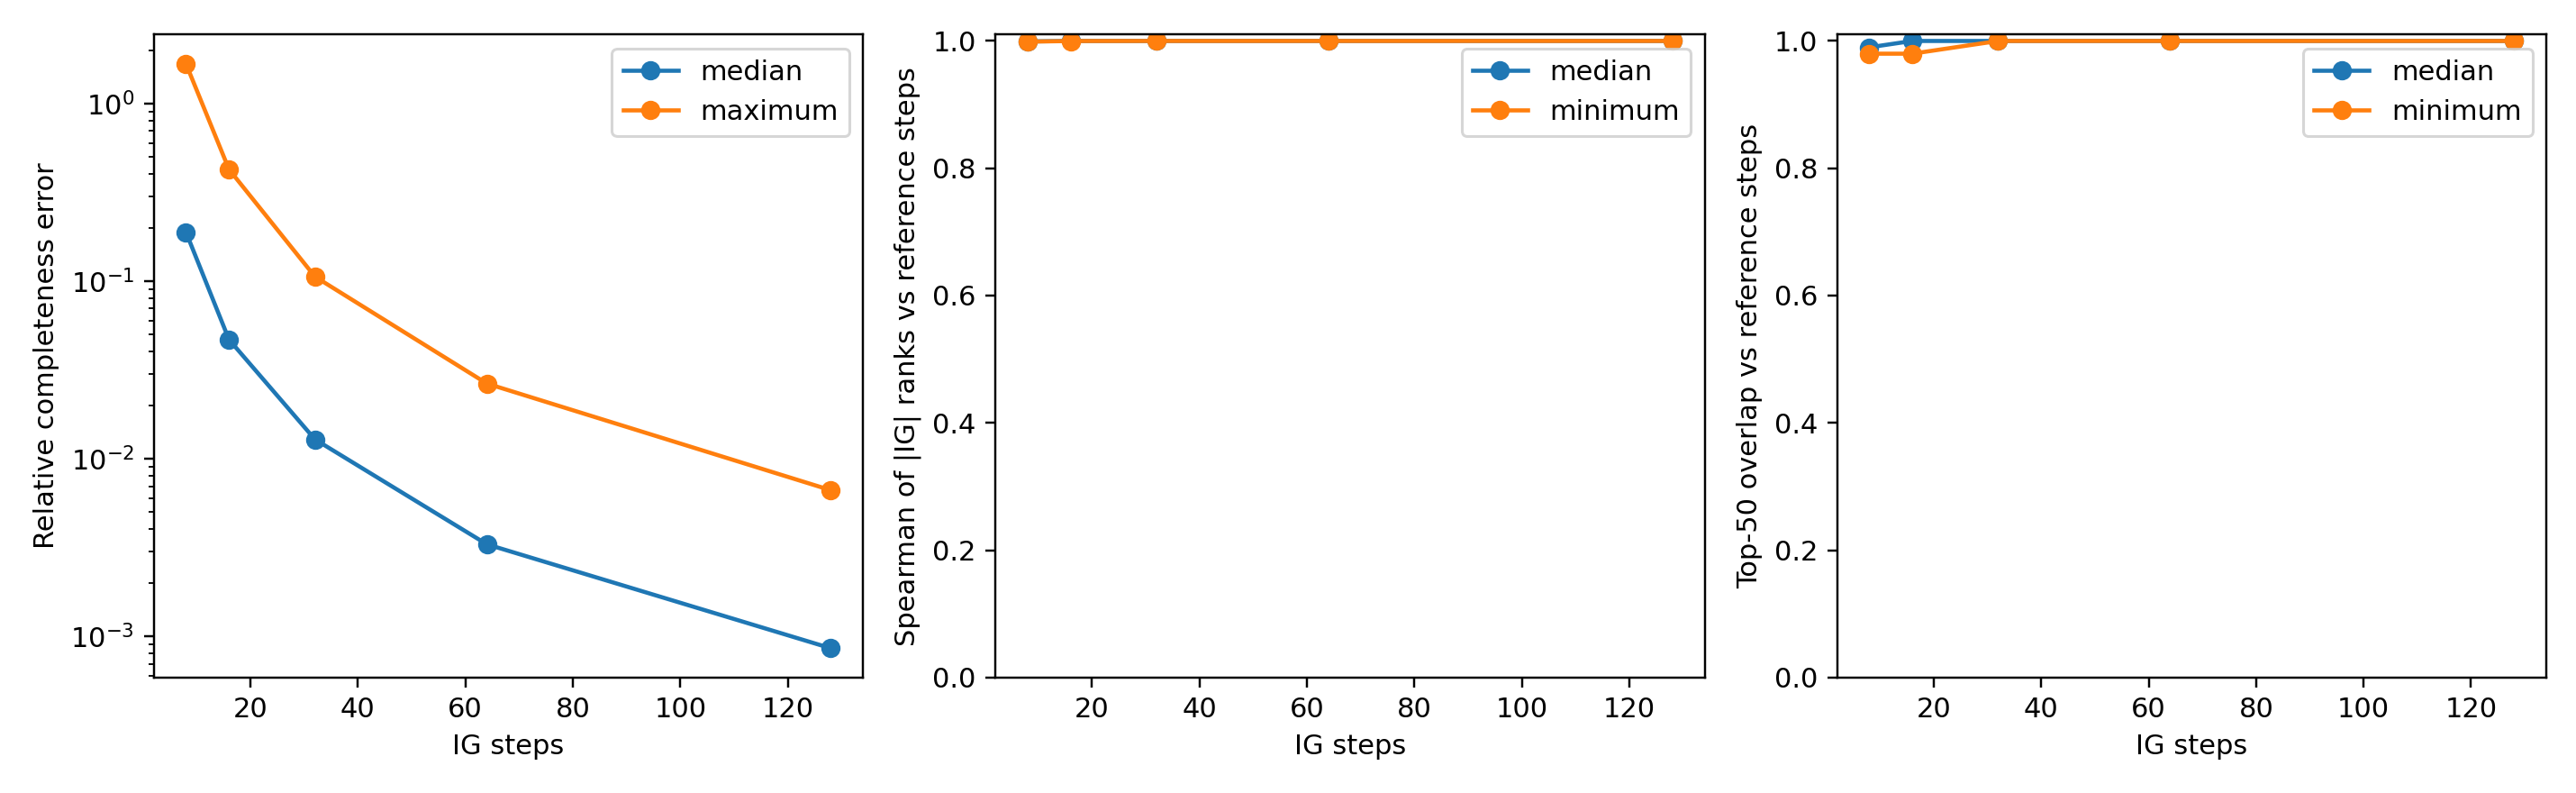

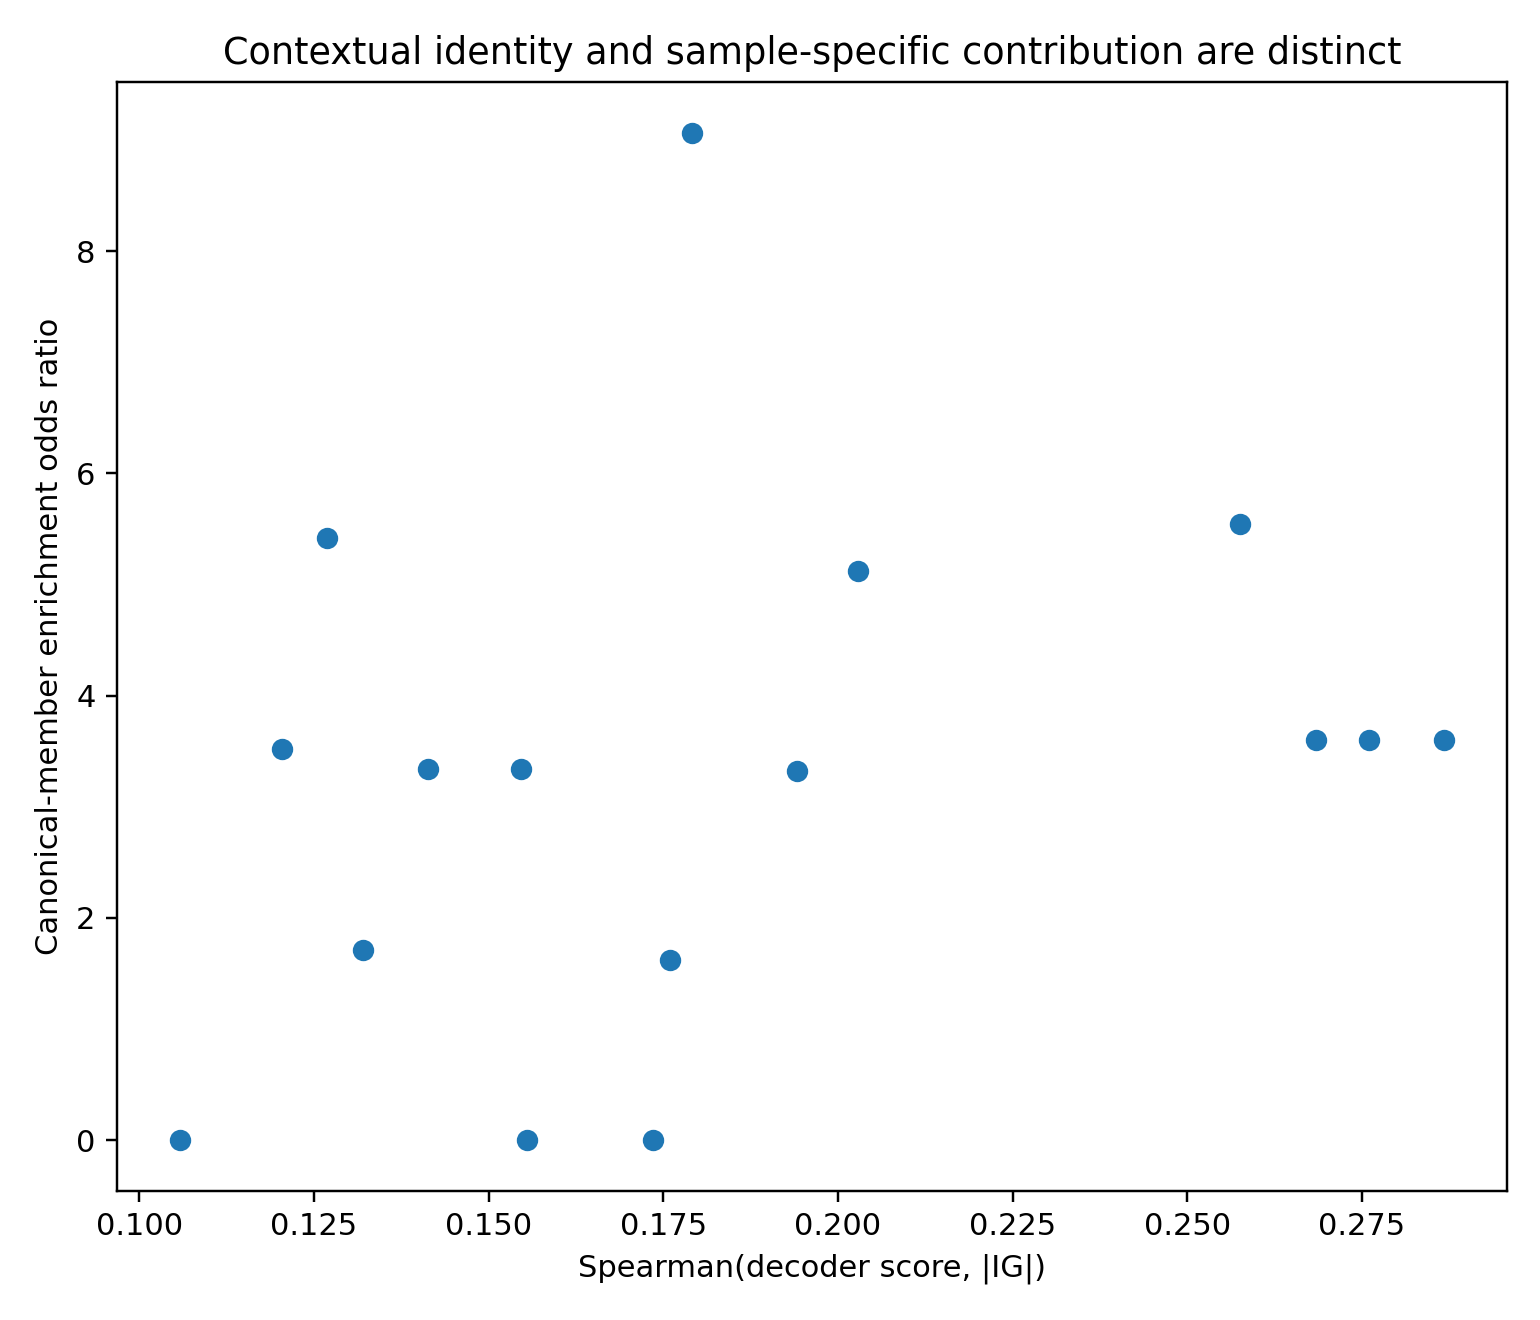

In [12]:
display(Image(filename=R/'ig_validation/ig_step_convergence.png')); display(Image(filename=R/'ig_validation/decoder_vs_validated_ig.png'))

## Pan-cancer Bridge versus conventional GSEA
Seven patient-disjoint primary-tumor subtype/site contrasts use identical samples, Welch statistics, Hallmark sets, and GSEA settings for the whole and vocabulary-matched universes. Adjacent-normal comparisons are not run because normals are absent from the frozen Bridge-profile cohort.

In [13]:
pan=pd.read_csv(R/'pan_cancer_gsea/pan_contrast_summary.csv')
per_contrast=pd.read_csv(R/'pan_cancer_gsea/per_contrast_agreement.csv')
pan, per_contrast

(        comparison  contrasts  median_pearson  pearson_iqr_low  \
 0  bridge_vs_whole          7        0.697168         0.605537   
 1  bridge_vs_vocab          7        0.720411         0.614399   
 2   whole_vs_vocab          7        0.981882         0.967617   
 
    pearson_iqr_high  median_spearman  spearman_iqr_low  spearman_iqr_high  \
 0          0.718478         0.705354          0.654310           0.772149   
 1          0.745214         0.711693          0.644178           0.800720   
 2          0.990566         0.987803          0.980024           0.990108   
 
    median_direction_agreement  positive_spearman_contrasts  \
 0                        0.82                            7   
 1                        0.82                            7   
 2                        0.98                            7   
 
    positive_spearman_proportion  median_top5_overlap  median_top10_overlap  
 0                           1.0                  0.4                   0.5  
 1    

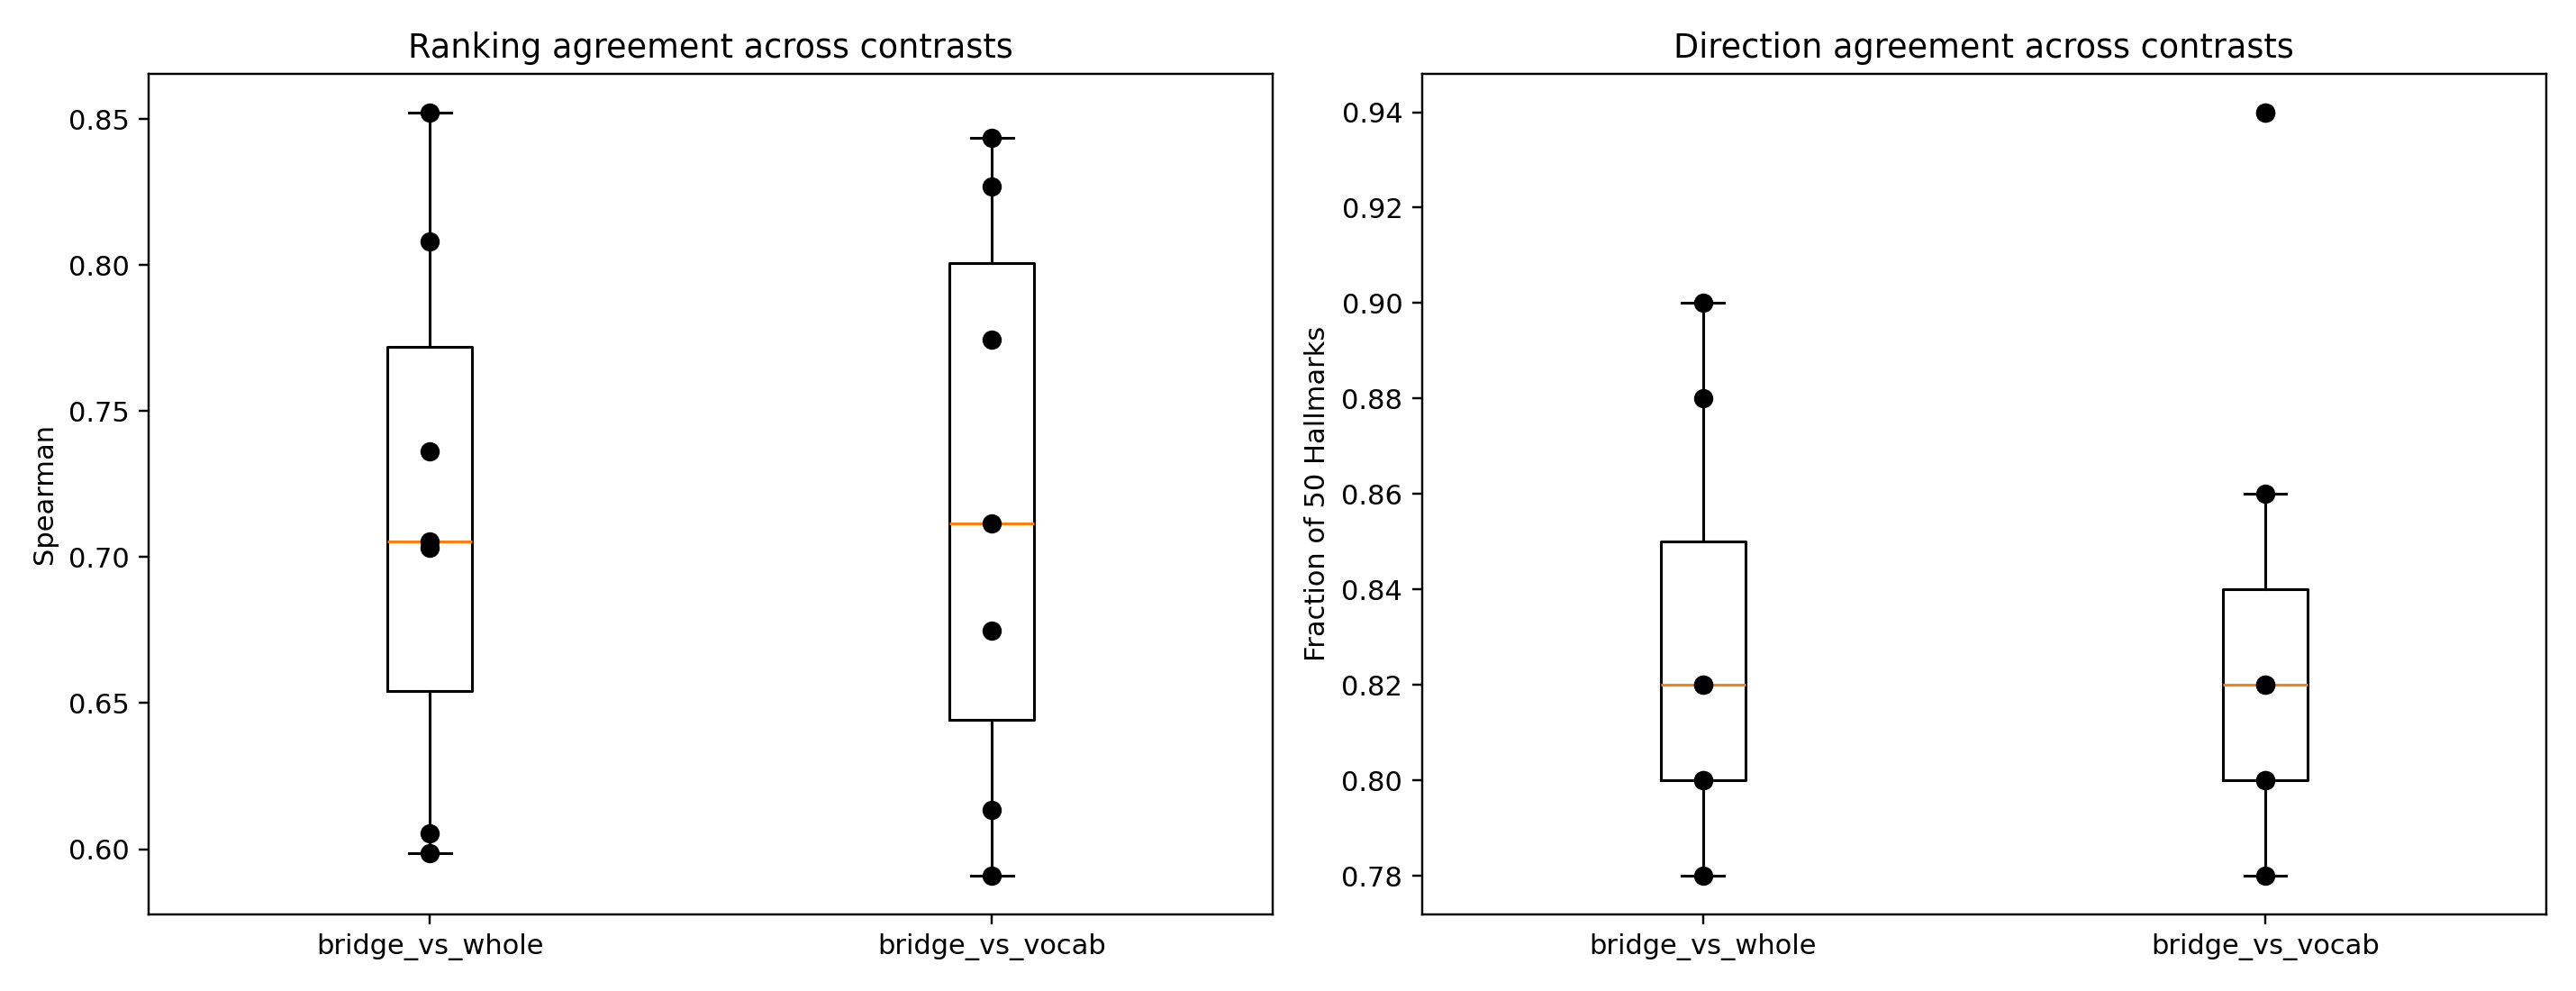

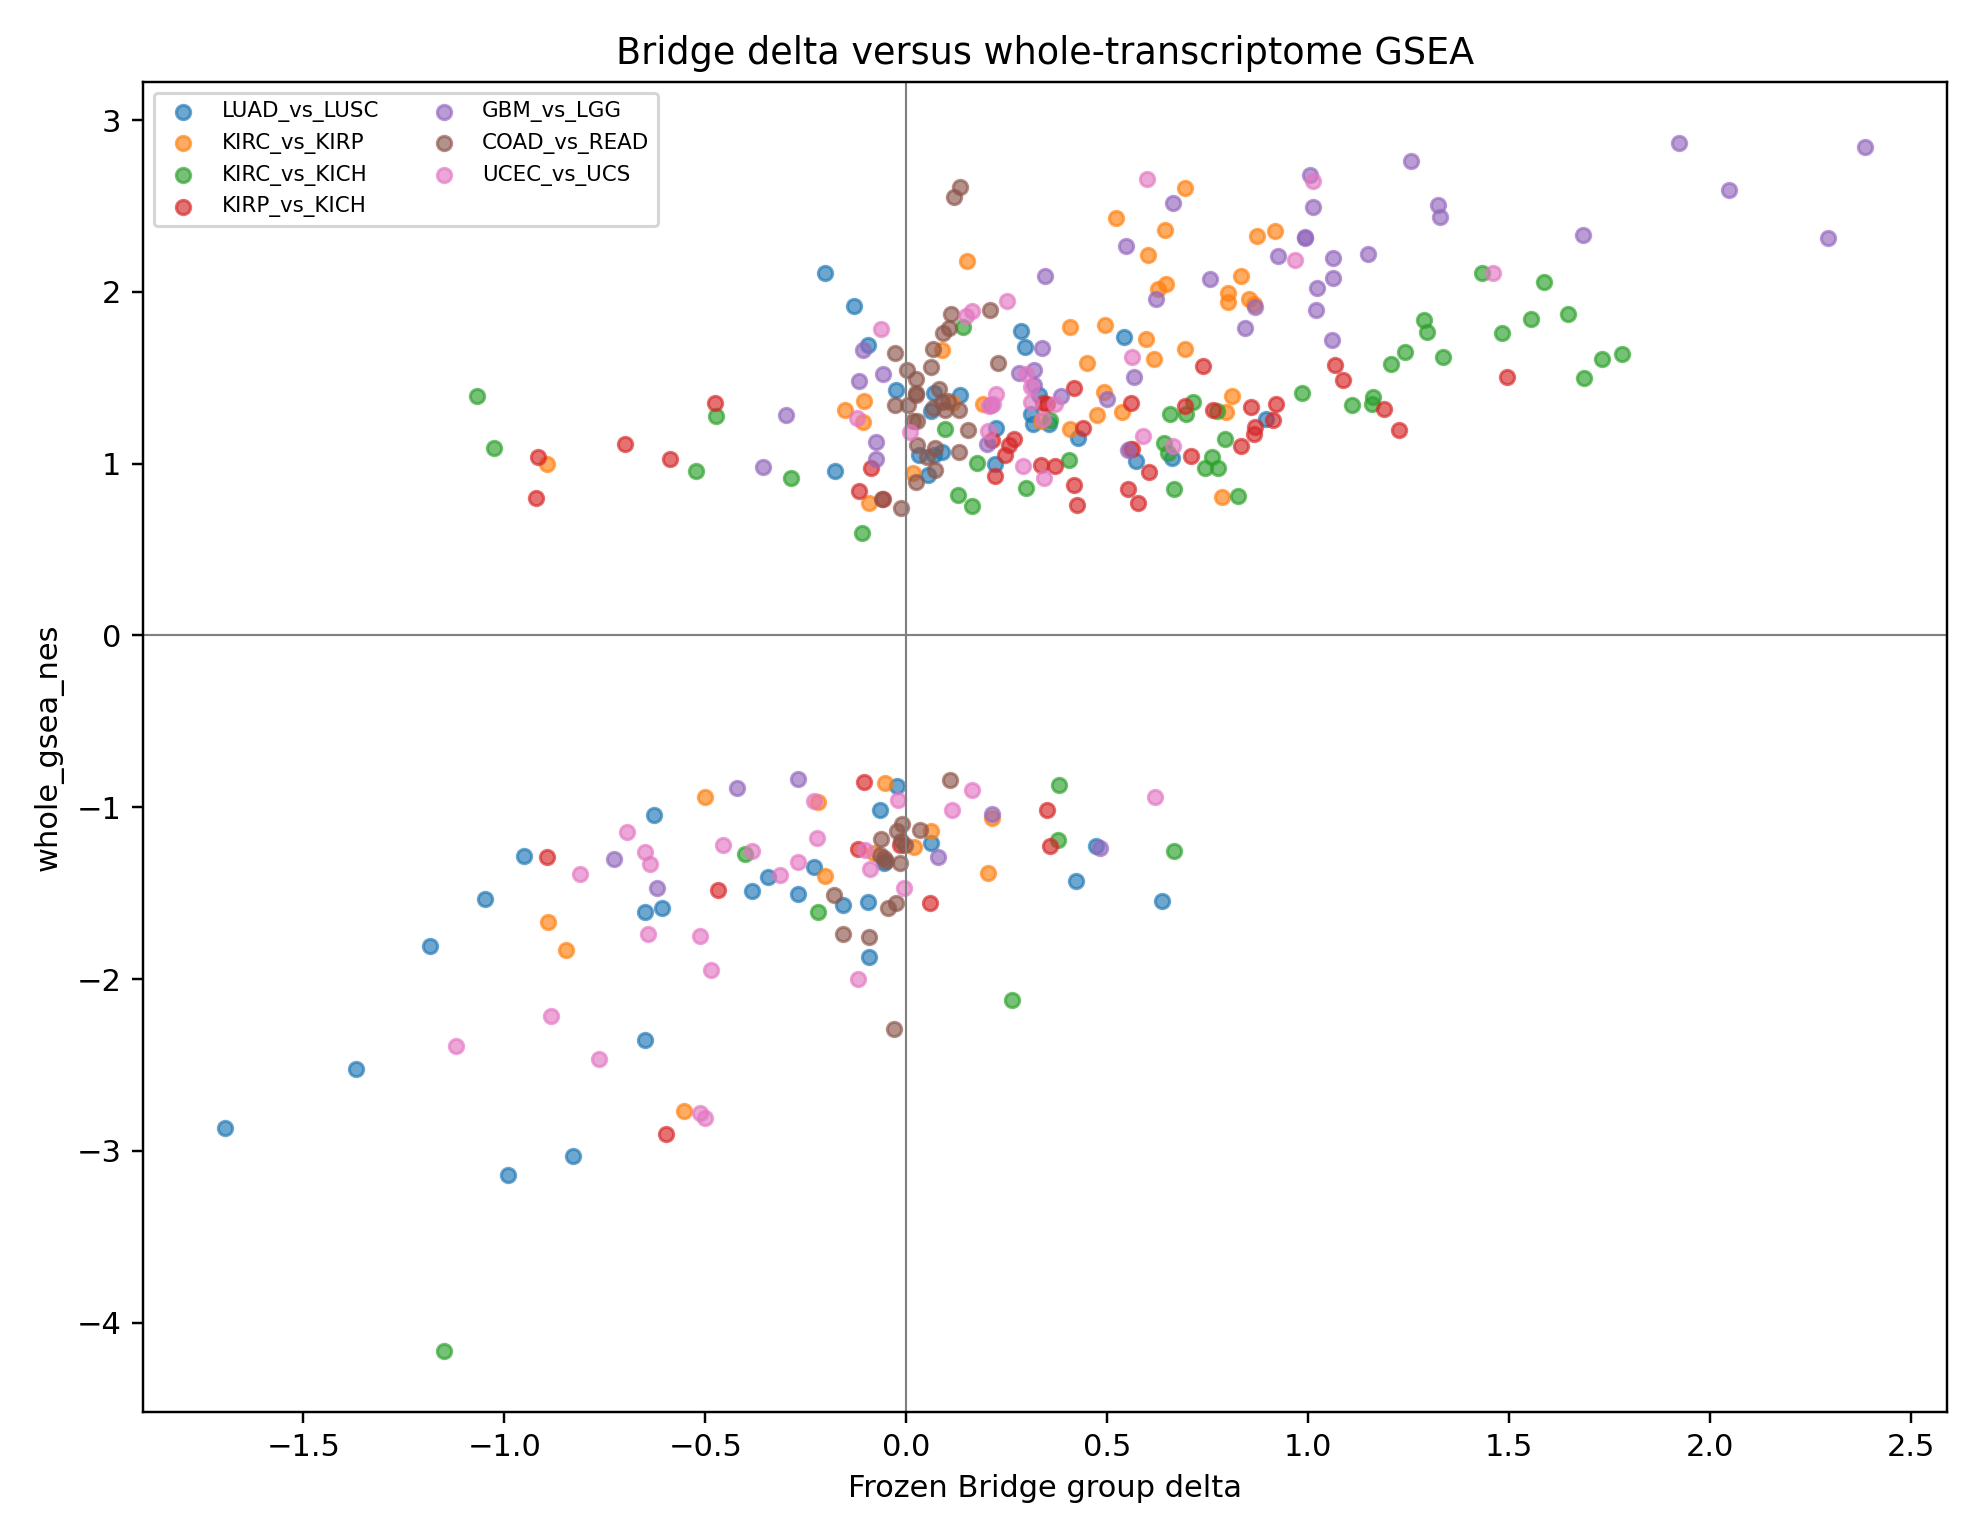

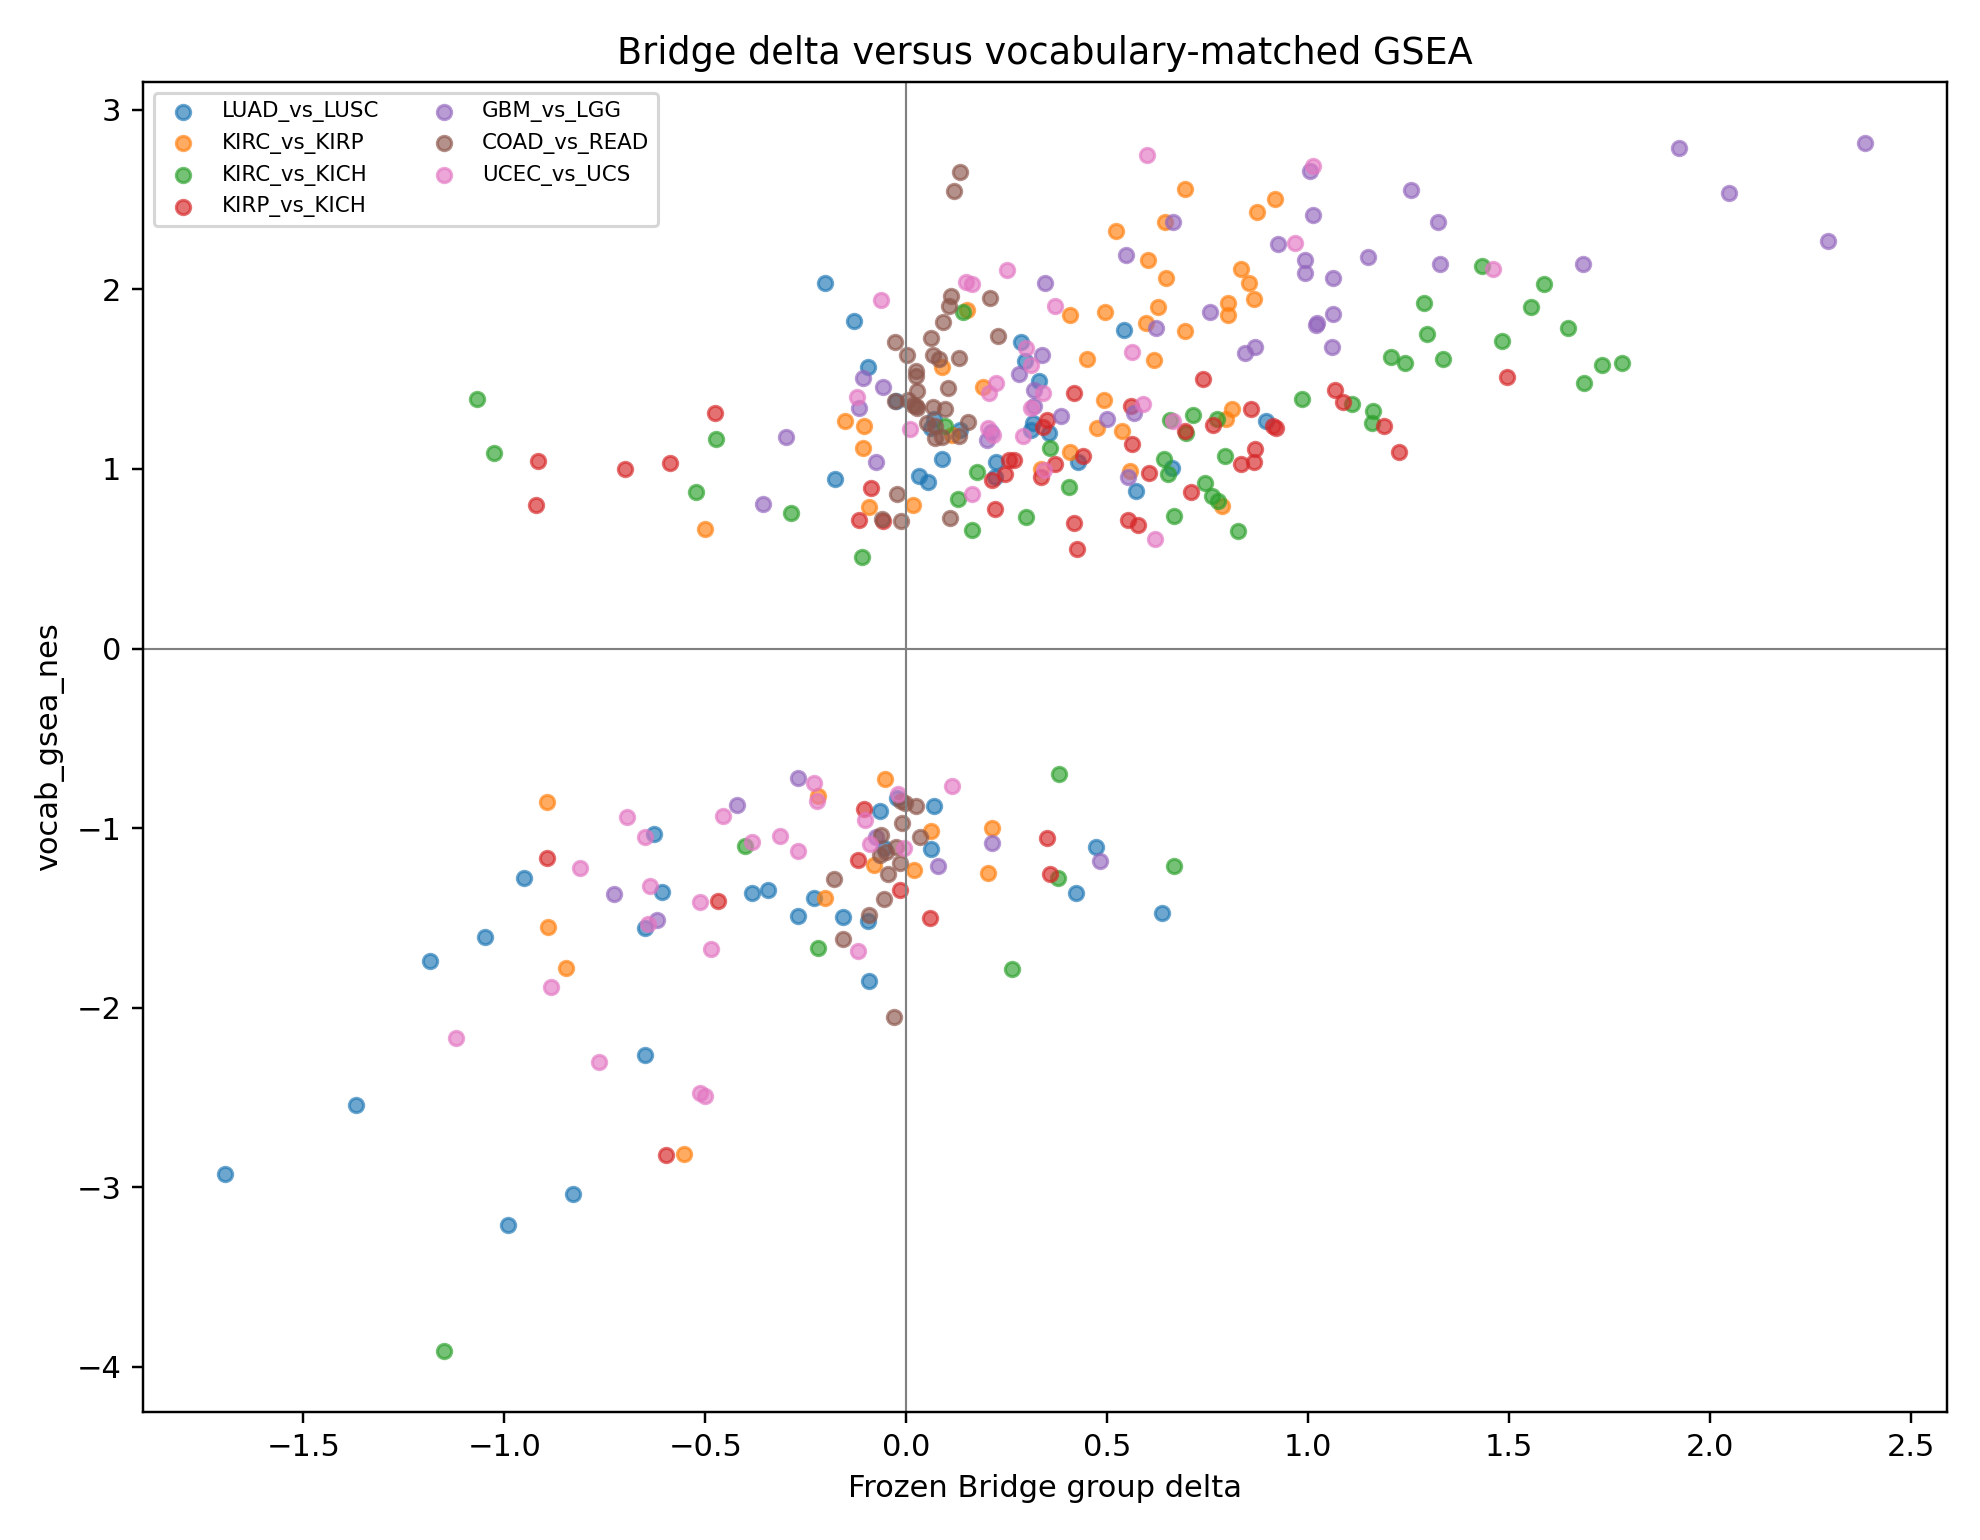

In [14]:
display(Image(filename=R/'pan_cancer_gsea/pan_contrast_agreement_summary.png')); display(Image(filename=R/'pan_cancer_gsea/bridge_vs_whole_all_contrasts.png')); display(Image(filename=R/'pan_cancer_gsea/bridge_vs_vocab_all_contrasts.png'))

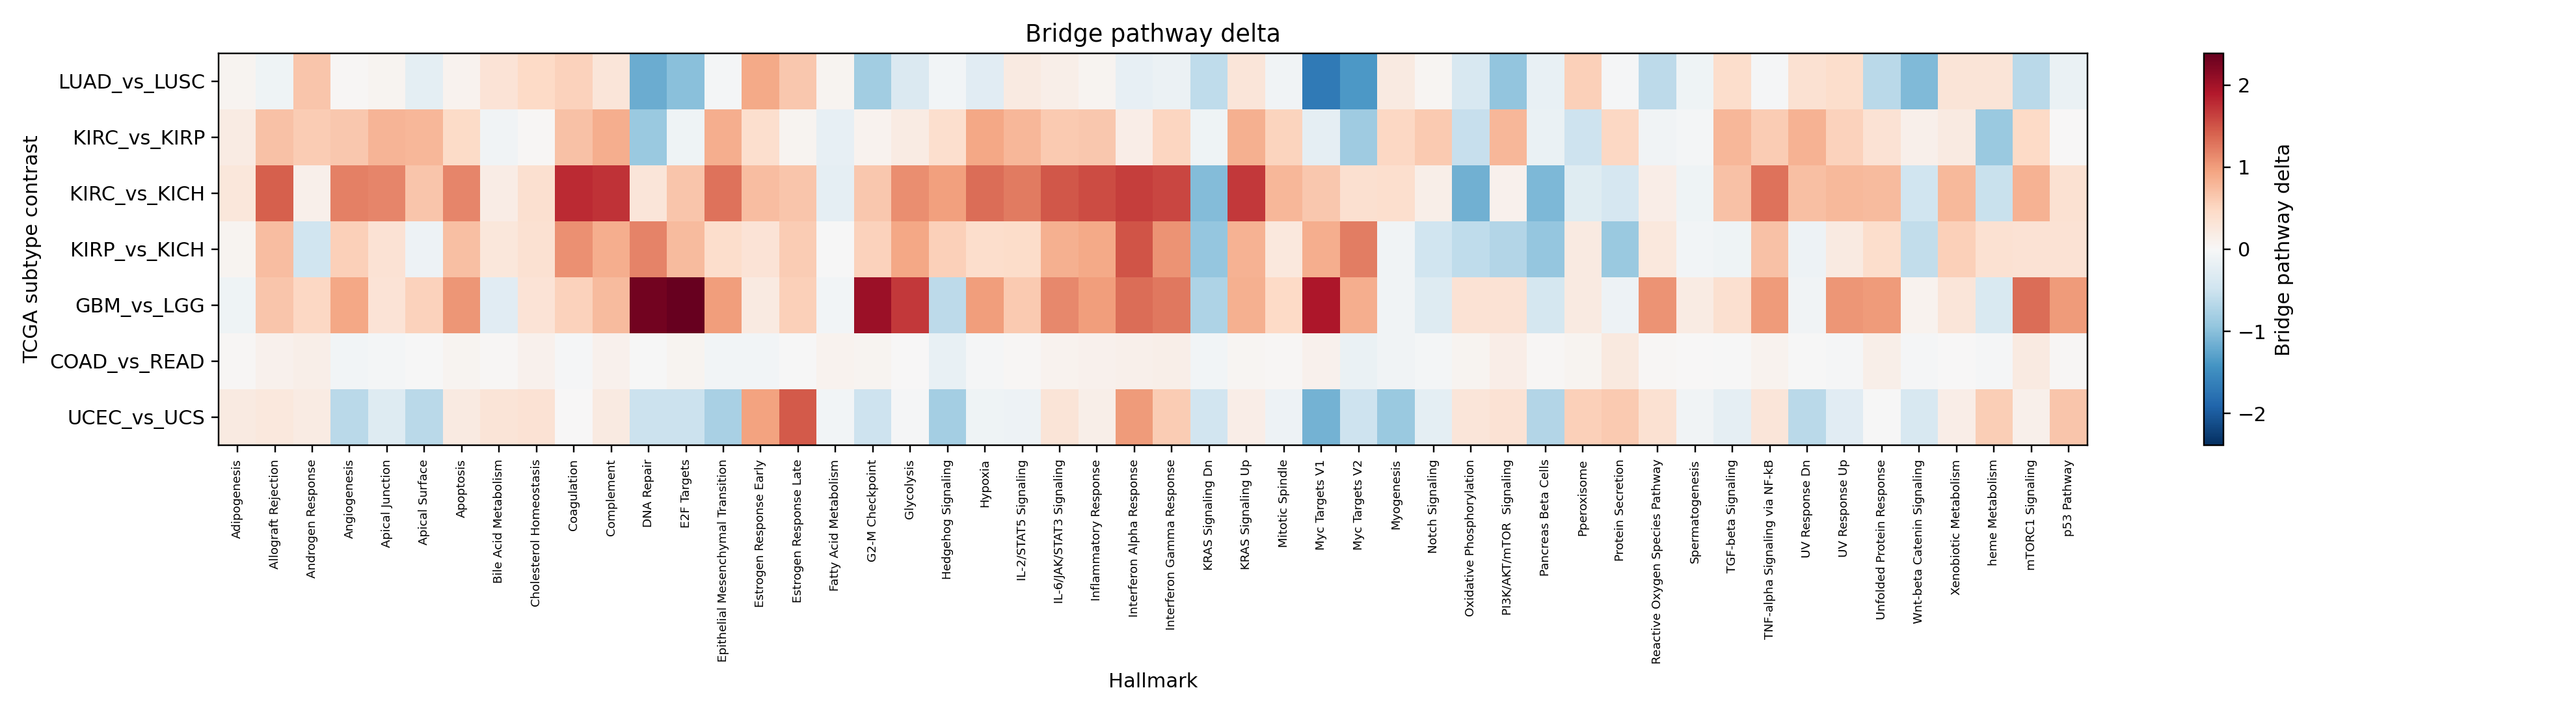

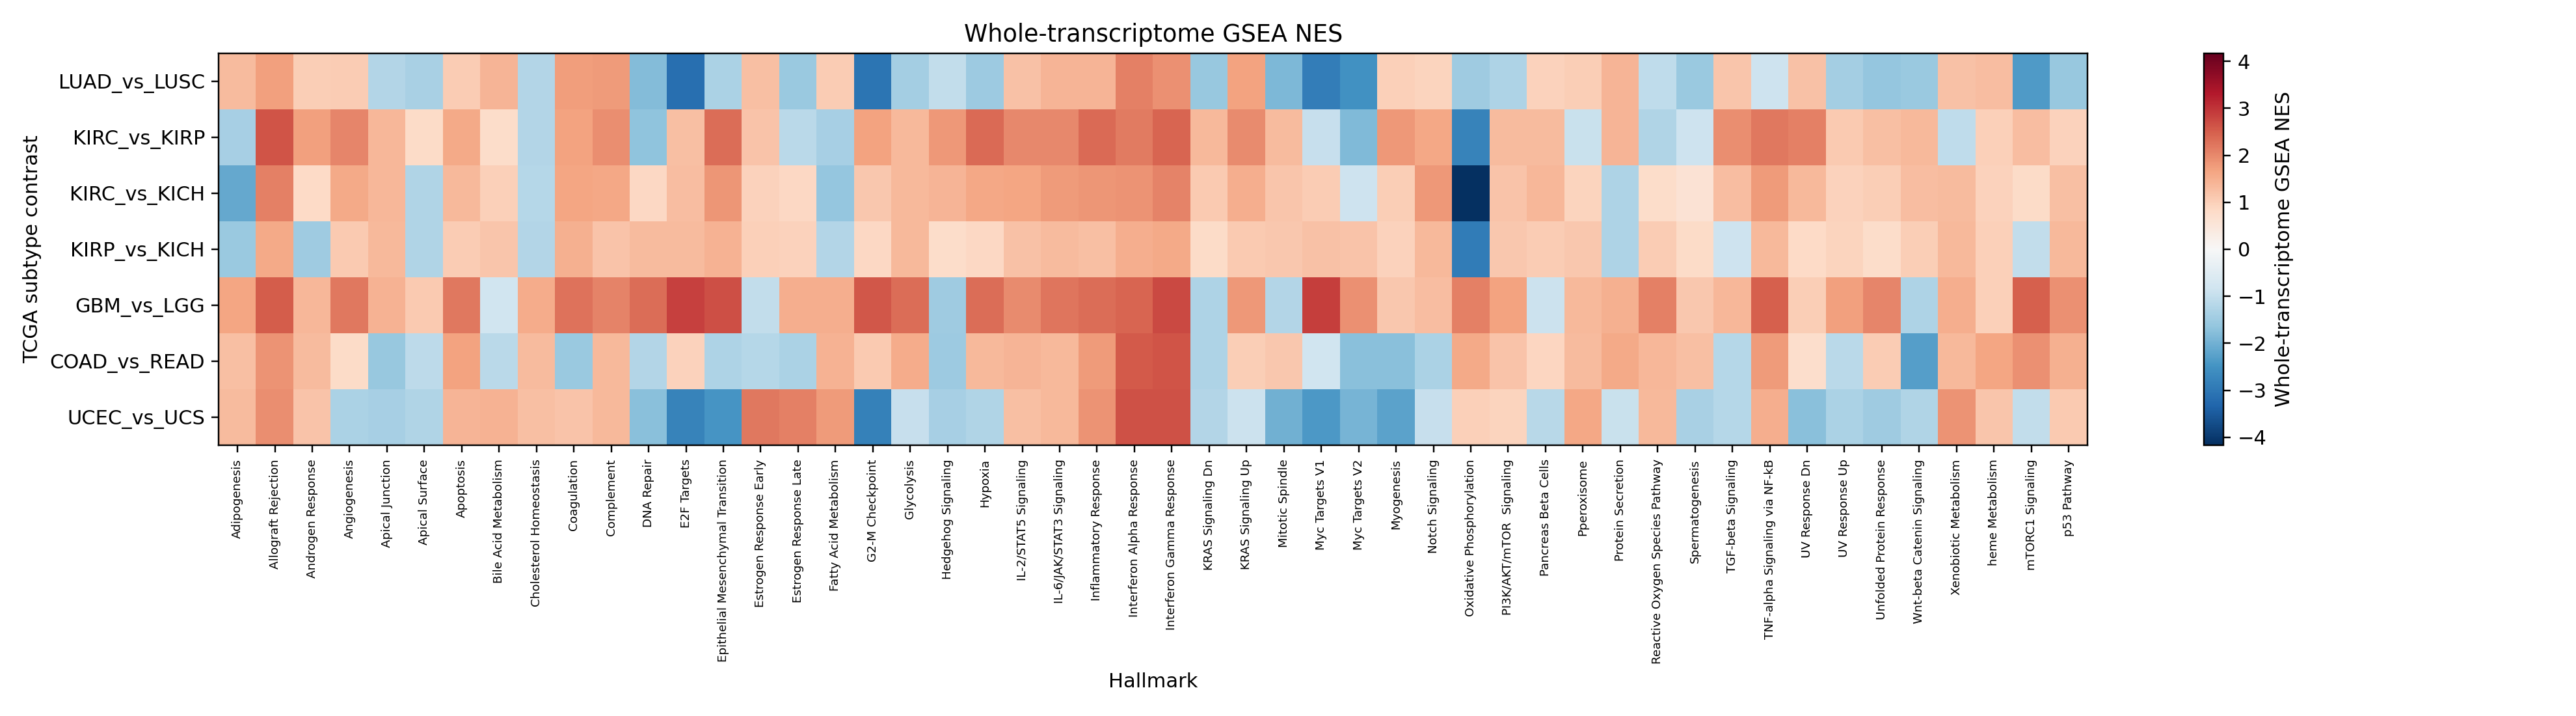

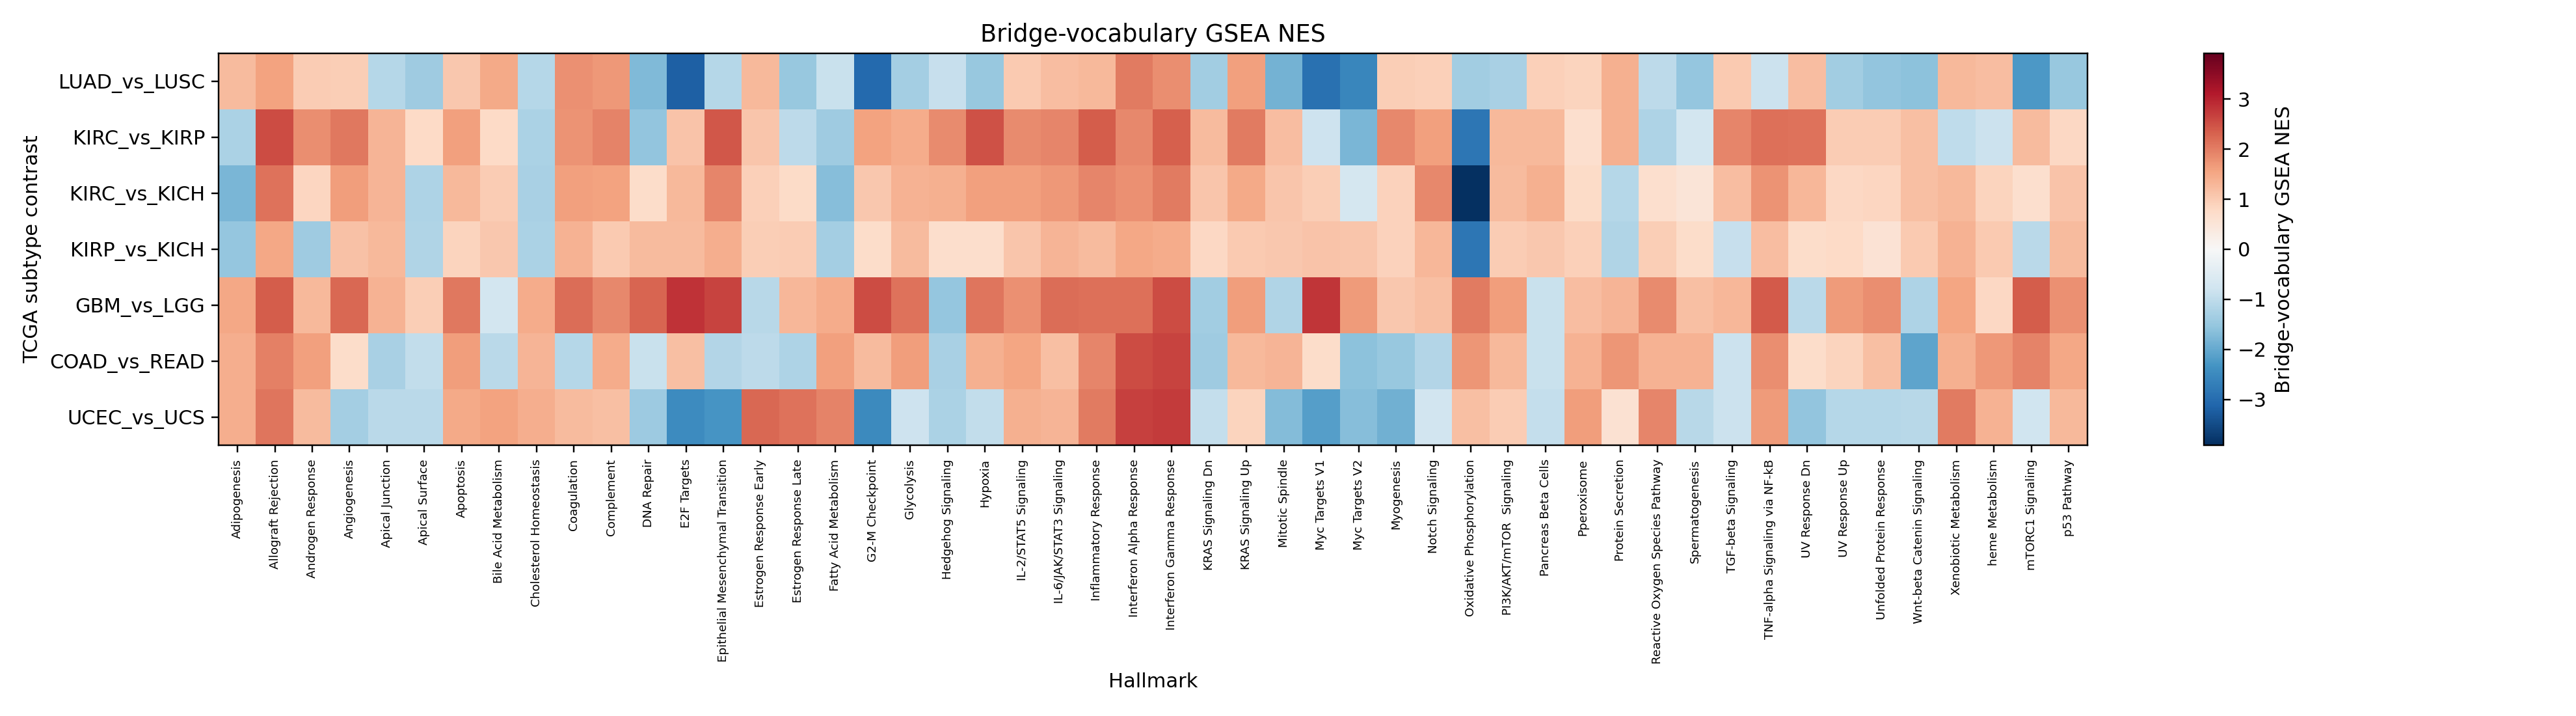

In [15]:
display(Image(filename=R/'pan_cancer_gsea/bridge_delta_heatmap.png')); display(Image(filename=R/'pan_cancer_gsea/whole_gsea_nes_heatmap.png')); display(Image(filename=R/'pan_cancer_gsea/vocab_gsea_nes_heatmap.png'))

## Exploratory matched organs
These cross-cohort displacements are not pure tumor effects.

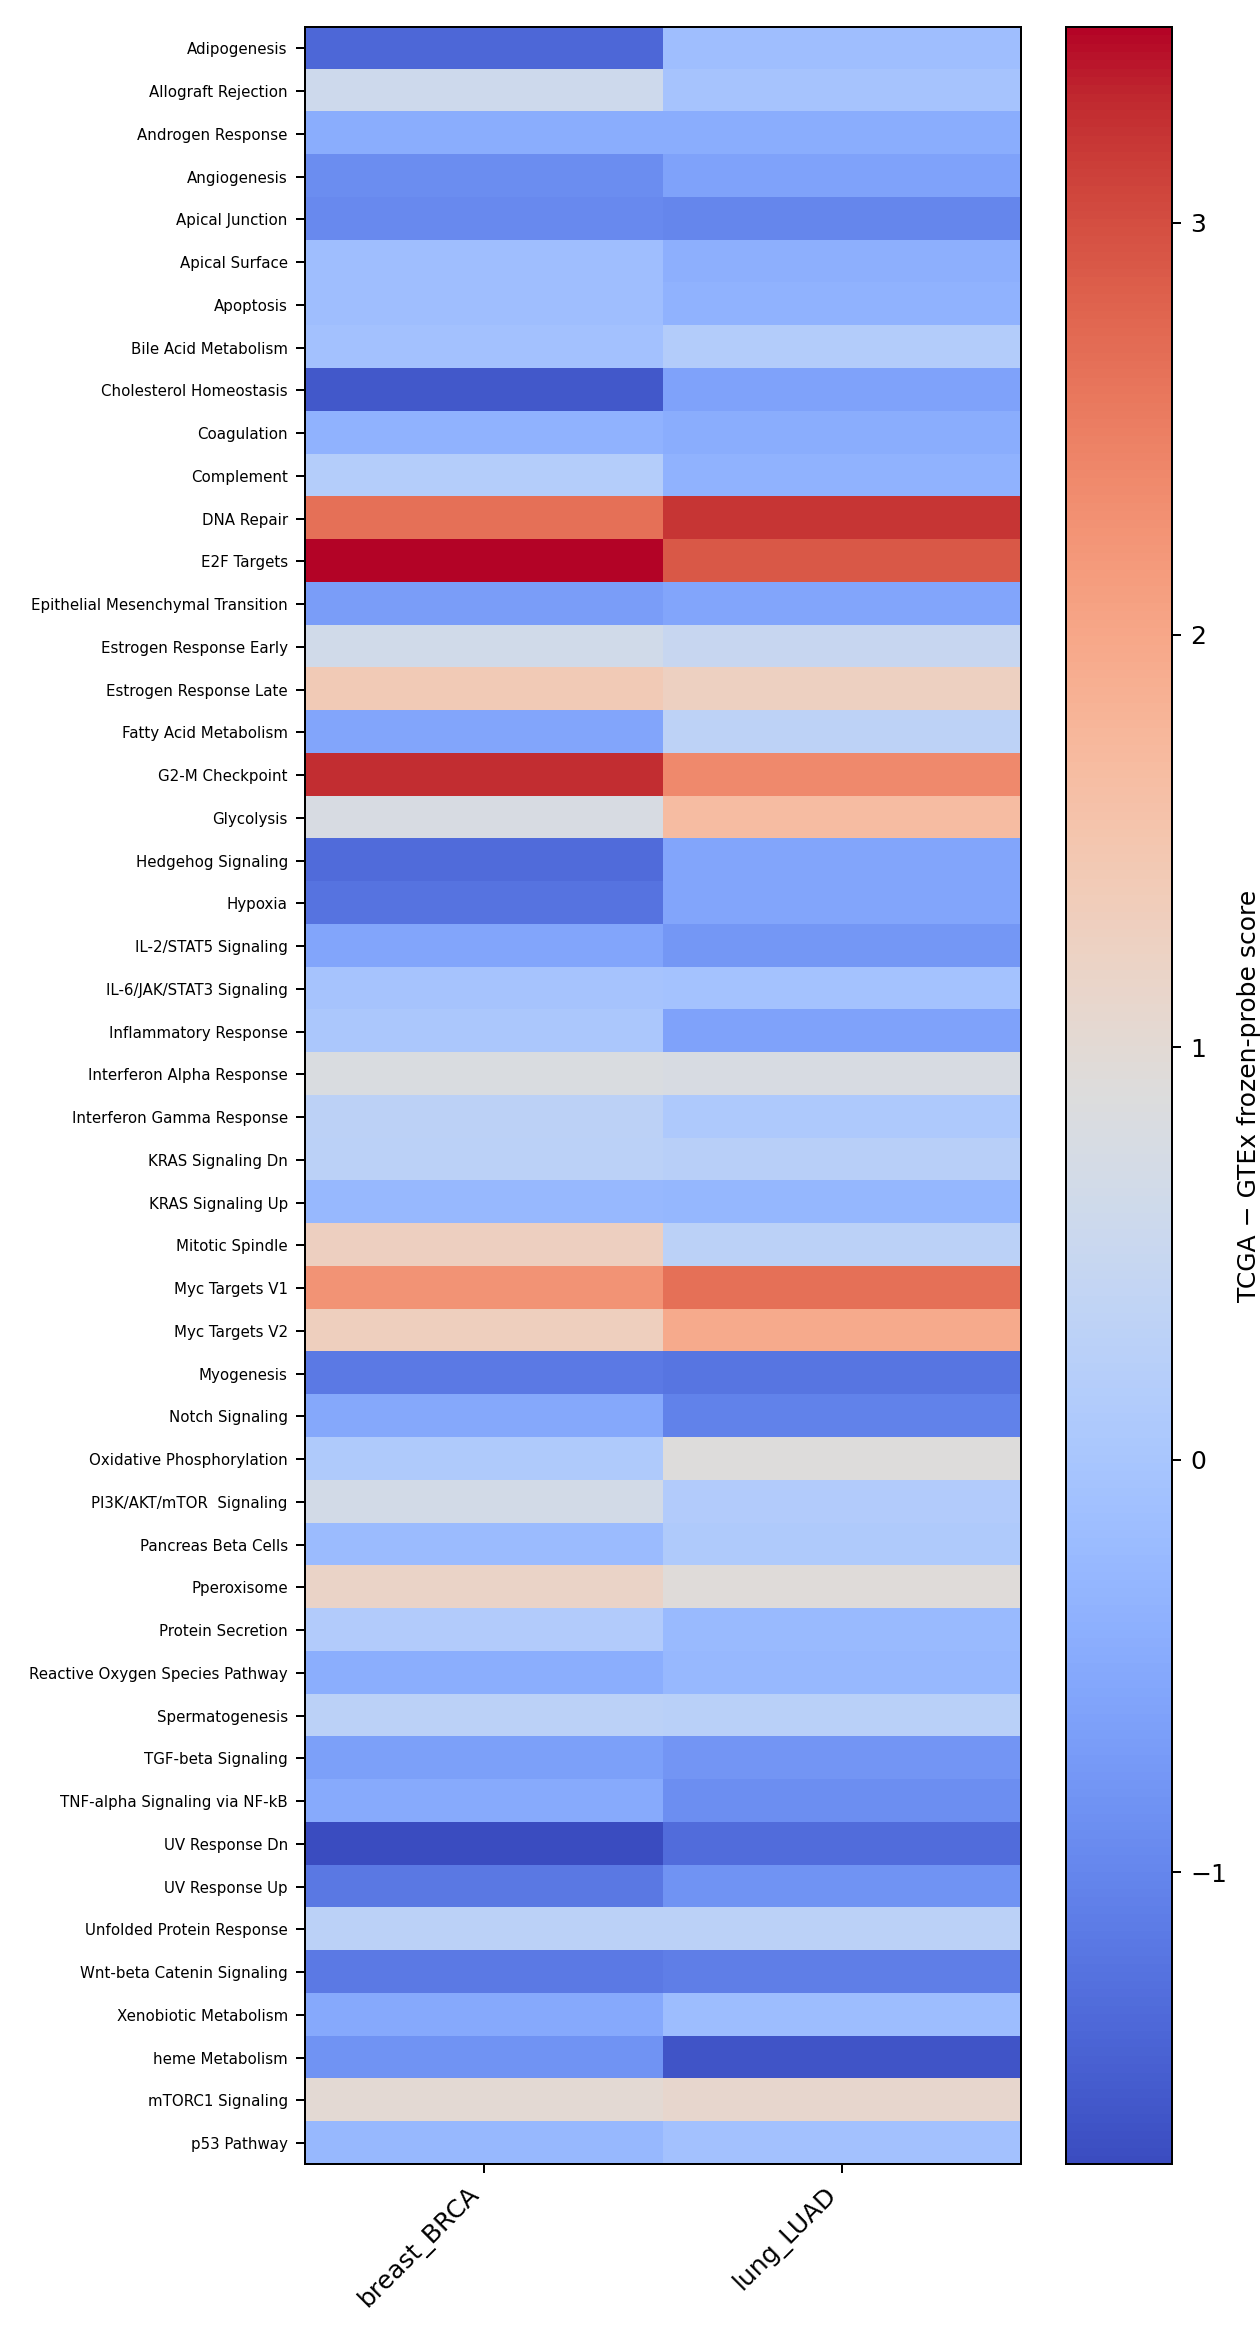

In [16]:
display(Image(filename=R/'exploratory_gtex_tcga_matched_organ_heatmap.png'))

## Limitations
GTEx/TCGA subtraction is cross-cohort and cannot identify pure tumor effects. Unexplained coordinates are not evidence of novel biology. Heatmap appearance is never treated as validation.